# Лабораторна робота №4: Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень

### Мета роботи:
Дослідити та порівняти три алгоритми класифікації — дерево рішень (Decision Tree), випадковий ліс (Random Forest) та градієнтний бустинг (XGBoost) — на реальному датасеті Annealing, що містить істотну частку пропущених значень. Основну увагу приділити:
* впливу способу обробки пропусків на якість класифікації (порівняння базової імпутації та імпутації з бінарними індикаторами пропусків);
* коректному (без витоку даних) підбору гіперпараметрів за допомогою фреймворку Optuna;
* неупередженому оцінюванню моделей за допомогою вкладеної крос-валідації (Nested Cross-Validation) та строгому статистичному порівнянню за скоригованим тестом Наде–Бенжіо;
* інтерпретації глобальної та локальної поведінки моделей за допомогою аналізу важливості ознак (MDI, Permutation Importance) та SHAP-значень для об'єктів розбіжностей прогнозів.

### Основний стек інструментів:
* **Python 3.12** — мова програмування для побудови аналітичного конвеєра.
* **Scikit-learn** — алгоритми попередньої обробки (`ColumnTransformer`, `SimpleImputer`, `MissingIndicator`, `OneHotEncoder`), моделі `DecisionTreeClassifier`, `RandomForestClassifier`, процедури крос-валідації та метрики якості.
* **XGBoost** — градієнтний бустинг другого порядку над деревами рішень (`XGBClassifier`).
* **Optuna** — сучасний фреймворк автоматичного байєсівського підбору гіперпараметрів на базі TPE-семплера (Tree-structured Parzen Estimator).
* **SHAP (SHapley Additive exPlanations)** — теоретико-ігрова інтерпретація прогнозів деревних моделей (`TreeExplainer`).
* **Pandas / Matplotlib / Seaborn / Scipy** — маніпуляція даними, статистичні критерії та візуалізація.

In [1]:
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Бібліотеки машинного навчання
import sklearn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    cross_validate,
    cross_val_score,
    cross_val_predict
)
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Градієнтний бустинг та оптимізація гіперпараметрів
import xgboost as xgb
from xgboost import XGBClassifier
import optuna
from optuna.visualization.matplotlib import (
    plot_optimization_history,
    plot_param_importances
)

# Інтерпретований ШІ (SHAP)
import shap

# Налаштування стилю та вимкнення зайвих попереджень
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Фіксація єдиного генератора випадковості за індивідуальним номером (N = 1 -> SEED = 43)
N_STUDENT = 1
SEED = 42 + N_STUDENT

print(f"Ініціалізація успішна. Базова константа випадковості SEED = 42 + {N_STUDENT} = {SEED}")
print(f"Версії бібліотек: scikit-learn={sklearn.__version__}, xgboost={xgb.__version__}, optuna={optuna.__version__}, shap={shap.__version__}")

Ініціалізація успішна. Базова константа випадковості SEED = 42 + 1 = 43
Версії бібліотек: scikit-learn=1.8.0, xgboost=3.4.1, optuna=5.0.0, shap=0.54.1


## 1. Первинний аналіз та розвідка даних (EDA)

### Механізми виникнення пропусків (Rubin, 1976):
У класичній теорії аналізу даних за класифікацією Дональда Рубіна розрізняють три фундаментальні механізми виникнення пропущених значень:
1. **MCAR (Missing Completely At Random)** — пропуск абсолютно випадковий. Ймовірність відсутності значення ознаки $X_j$ не залежить ані від спостережуваних значень інших ознак, ані від самого прихованого значення $X_j$. У цьому випадку видалення або проста імпутація не призводять до зміщення оцінок параметрів.
2. **MAR (Missing At Random)** — пропуск є випадковим за умови спостережуваних даних. Ймовірність пропуску в $X_j$ залежить від значень інших доступних ознак (наприклад, від класу виробу чи технологічного типу сталі), але не від самого неспостережуваного значення $X_j$.
3. **MNAR (Missing Not At Random)** — пропуск є невипадковим. Ймовірність пропуску безпосередньо залежить від самого прихованого значення або від неврахованих латентних чинників.

### Структурні пропуски та ефект стелі:
У промислових датасетах, таких як **Annealing** (параметри металургійного процесу відпалу сталі), значна частина пропусків є **структурними**: певний технологічний тест чи параметр покриття просто не застосовується для сталі заданої марки чи форми. Сам факт наявності чи відсутності значення містить потужний предиктивний сигнал щодо цільового класу. Саме тому введення бінарних індикаторів пропусків (`MissingIndicator`) здатне кардинально змінити якість дерева рішень.

Крім того, на датасеті Annealing моделі на базі дерев зазвичай демонструють дуже високу точність (близьку до 99–100%), що спричиняє **ефект стелі (ceiling effect)**: різниці між якісними моделями стають мінімальними, тому критично важливим є використання зважених метрик (`Macro-F1`, `Balanced Accuracy`), розрахунок дисперсії та проведення строгого статистичного тестування різниць.

Завантаження датасету Annealing з репозиторію OpenML (версія 1)...
Розмірність завантаженого датасету: 898 спостережень, 38 ознак.
Використано версію OpenML (898 спостережень).

Аналіз порожніх та константних колонок:
Повністю порожні ознаки (100% NaN): ['m', 'marvi', 'corr', 'jurofm', 's', 'p']
Константні ознаки (<=1 унікальне значення): ['product-type', 'm', 'marvi', 'corr', 'jurofm', 's', 'p']
Разом видаляється ознак: 7 (['corr', 'jurofm', 'p', 'm', 's', 'marvi', 'product-type'])
Розмірність матриці ознак після очищення: 898 рядків, 31 ознак.

Розподіл класів цільової змінної y:
  Клас '1':   8 спостережень ( 0.89%)
  Клас '2':  99 спостережень (11.02%)
  Клас '3': 684 спостережень (76.17%)
  Клас '5':  67 спостережень ( 7.46%)
  Клас 'U':  40 спостережень ( 4.45%)


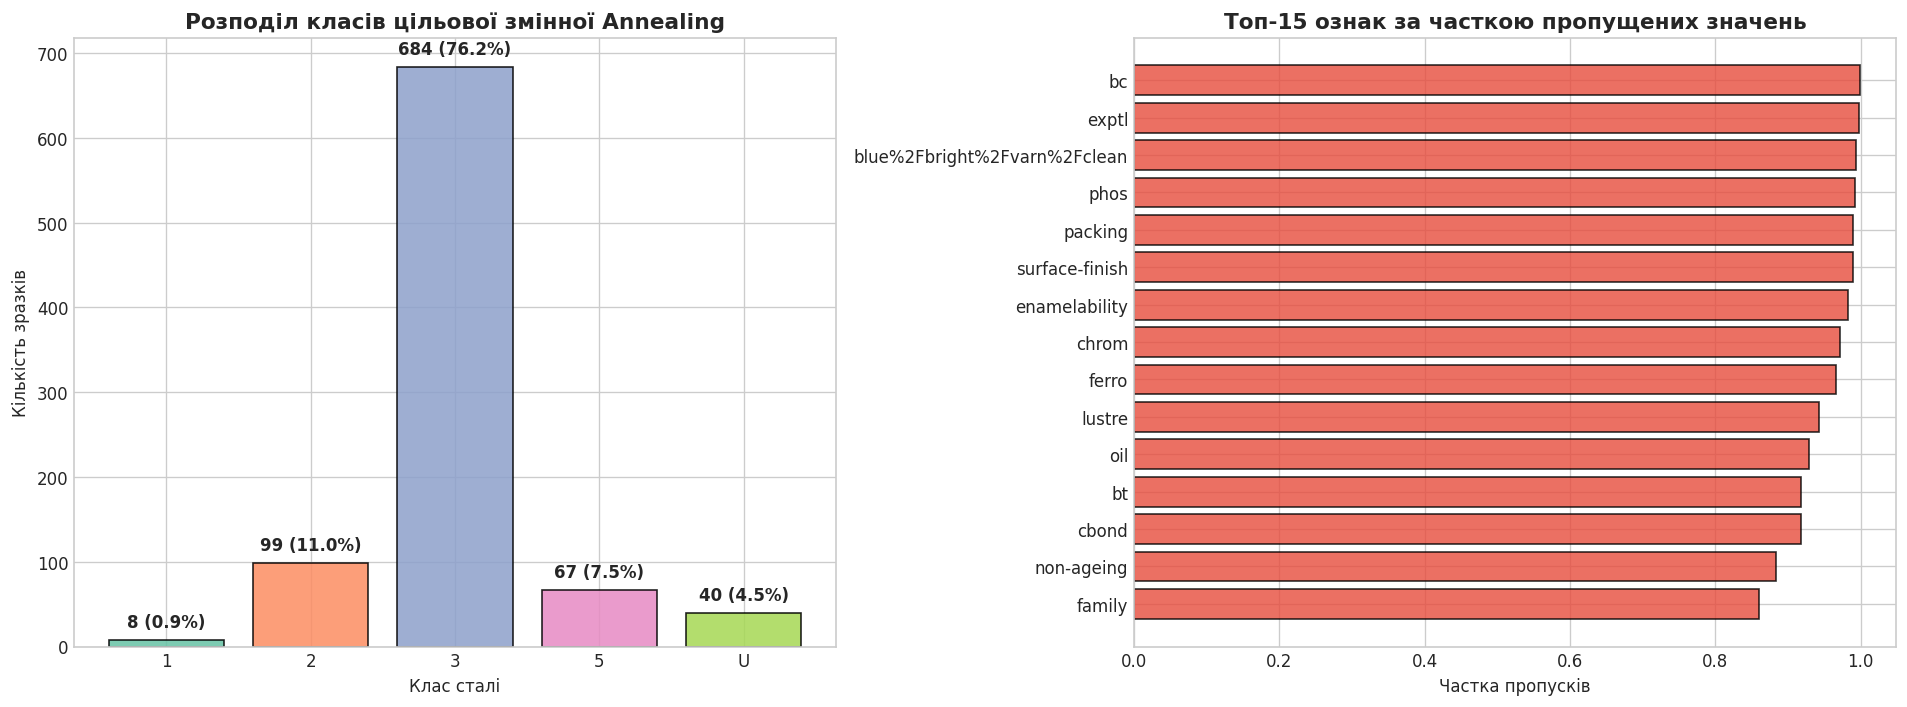

In [2]:
# Завантаження датасету Annealing з OpenML
print("Завантаження датасету Annealing з репозиторію OpenML (версія 1)...")
data = fetch_openml(name='anneal', version=1, as_frame=True)
X_raw, y_raw = data.data, data.target

print(f"Розмірність завантаженого датасету: {X_raw.shape[0]} спостережень, {X_raw.shape[1]} ознак.")
print("Використано версію OpenML (898 спостережень).")

# 1. Приведення категоріальних ознак до типу object
X = X_raw.copy()
for col in X.select_dtypes(exclude='number').columns:
    X[col] = X[col].astype('object')

# 2. Обчислення частки пропусків для кожної ознаки
missing_series = X.isnull().mean()
missing_counts = X.isnull().sum()

# Виявлення повністю порожніх (100% пропусків) та константних ознак
empty_cols = list(missing_series[missing_series == 1.0].index)
constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
cols_to_drop = list(set(empty_cols + constant_cols))

print("\nАналіз порожніх та константних колонок:")
print(f"Повністю порожні ознаки (100% NaN): {empty_cols}")
print(f"Константні ознаки (<=1 унікальне значення): {constant_cols}")
print(f"Разом видаляється ознак: {len(cols_to_drop)} ({cols_to_drop})")

# Видалення неінформативних колонок
X = X.drop(columns=cols_to_drop)
print(f"Розмірність матриці ознак після очищення: {X.shape[0]} рядків, {X.shape[1]} ознак.")

# Розподіл цільової змінної
target_counts = y_raw.value_counts().sort_index()
target_pct = (y_raw.value_counts(normalize=True) * 100).sort_index()

print("\nРозподіл класів цільової змінної y:")
for cls_name, count in target_counts.items():
    print(f"  Клас '{cls_name}': {count:3d} спостережень ({target_pct[cls_name]:5.2f}%)")

# Візуалізація: Розподіл класів та частка пропусків за ознаками
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Графік 1: Баланс класів
colors = sns.color_palette('Set2', len(target_counts))
bars = axes[0].bar(target_counts.index.astype(str), target_counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title('Розподіл класів цільової змінної Annealing', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Клас сталі')
axes[0].set_ylabel('Кількість зразків')
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 10, f"{int(yval)} ({yval/len(y_raw)*100:.1f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Графік 2: Частка пропусків по збережених ознаках (топ-15 найбільш розріджених)
valid_missing = X.isnull().mean().sort_values(ascending=False).head(15)
axes[1].barh(range(len(valid_missing)), valid_missing.values, color='#e74c3c', alpha=0.8, edgecolor='black')
axes[1].set_yticks(range(len(valid_missing)))
axes[1].set_yticklabels(valid_missing.index, fontsize=10)
axes[1].set_title('Топ-15 ознак за часткою пропущених значень', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Частка пропусків')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### Обґрунтування рішення щодо рідкісних класів та крос-валідації:

Аналіз розподілу цільової змінної показує суттєвий багатокласовий дисбаланс: домінуючий клас `3` охоплює 684 зразки (76.17%), тоді як класи `2`, `5`, `U` містять 99, 67 та 40 зразків відповідно, а найменший клас `1` налічує лише 8 спостережень (0.89%). Один із теоретично можливих класів (`4`), описаних у первинній металургійній документації, у даних OpenML взагалі відсутній.

У подібних ситуаціях перед дослідником постає вибір: виключити рідкісний клас `1`, об'єднати його з іншим чи залишити. У даній роботі прийнято рішення **залишити всі 5 класів**, що суворо відповідає постановці реальної задачі. При стратифікованому розбитті вибірки у співвідношенні 80/20 до навчального набору потрапляє 6 спостережень класу `1`, а до тестового — 2. 

Використання 5-блочної зовнішньої крос-валідації гарантує, що у кожному зовнішньому валідаційному блоці буде присутній щонайменше один зразок класу `1` (а у тренувальній частині — 4 або 5 зразків). У свою чергу, використання саме **3-блочної внутрішньої крос-валідації** у функції Optuna гарантує, що кожна з 3 внутрішніх тренувальних підпапок отримає від 2 до 3 зразків цього класу. Це повністю запобігає виникненню критичних помилок бібліотеки `XGBoost`, яка вимагає наявності представників усіх класів у кожному навчальному батчі.

In [3]:
# 5. Аналіз механізму пропусків (тест хі-квадрат для зв'язку між пропуском та класом)
top_missing_features = X.isnull().mean().sort_values(ascending=False).head(5).index.tolist()
print("="*80)
print("АНАЛІЗ МЕХАНІЗМУ ПРОПУСКІВ: ТАБЛИЦІ СПРЯЖЕНОСТІ ТА КРИТЕРІЙ ХІ-КВАДРАТ")
print("="*80)

missing_test_results = []

for feat in top_missing_features:
    # Бінарна ознака наявності пропуску
    is_miss = X[feat].isnull().map({True: 'Пропуск (Missing)', False: 'Наявне (Present)'})
    contingency_tab = pd.crosstab(is_miss, y_raw)
    
    chi2_val, p_val, dof, _ = stats.chi2_contingency(contingency_tab)
    is_significant = p_val < 0.05
    mechanism_hypothesis = "MAR / MNAR (Залежність є)" if is_significant else "Схоже на MCAR (Незалежні)"
    
    missing_test_results.append({
        'Ознака': feat,
        'Частка пропусків': f"{X[feat].isnull().mean():.4f}",
        'Chi2-статистика': f"{chi2_val:.4f}",
        'p-значення': f"{p_val:.4e}",
        'Ступені свободи': dof,
        'Висновок щодо гіпотези': mechanism_hypothesis
    })
    
    print(f"\nТаблиця спряженості для ознаки '{feat}':")
    display(contingency_tab)

print("\nЗведена таблиця перевірки гіпотези незалежності пропусків від цільового класу:")
df_missing_tests = pd.DataFrame(missing_test_results)
display(df_missing_tests)

# 6. Кодування цільової змінної за допомогою LabelEncoder (вимога XGBoost)
le = LabelEncoder()
y_enc = le.fit_transform(y_raw)
class_mapping = dict(zip(range(len(le.classes_)), le.classes_))
print(f"\nВідповідність закодованих міток класам: {class_mapping}")

АНАЛІЗ МЕХАНІЗМУ ПРОПУСКІВ: ТАБЛИЦІ СПРЯЖЕНОСТІ ТА КРИТЕРІЙ ХІ-КВАДРАТ

Таблиця спряженості для ознаки 'bc':


class,1,2,3,5,U
bc,,,,,
Наявне (Present),0,0,1,0,0
Пропуск (Missing),8,99,683,67,40



Таблиця спряженості для ознаки 'exptl':


class,1,2,3,5,U
exptl,,,,,
Наявне (Present),2,0,0,0,0
Пропуск (Missing),6,99,684,67,40



Таблиця спряженості для ознаки 'blue%2Fbright%2Fvarn%2Fclean':


class,1,2,3,5,U
blue%2Fbright%2Fvarn%2Fclean,,,,,
Наявне (Present),1,4,1,0,0
Пропуск (Missing),7,95,683,67,40


... (3 outputs left out)

class,1,2,3,5,U
packing,,,,,
Наявне (Present),0,0,9,0,0
Пропуск (Missing),8,99,675,67,40



Зведена таблиця перевірки гіпотези незалежності пропусків від цільового класу:


,Ознака,Частка пропусків,Chi2-статистика,p-значення,Ступені свободи,Висновок щодо гіпотези
0,bc,0.9989,0.3132,9.8895e-01,4,Схоже на MCAR (Незалежні)
1,exptl,0.9978,222.9967,4.2466e-47,4,MAR / MNAR (Залежність є)
2,blue%2Fbright%2Fvarn%2Fclean,0.9933,37.3654,1.5146e-07,4,MAR / MNAR (Залежність є)
3,phos,0.9922,87.5030,4.4645e-18,4,MAR / MNAR (Залежність є)
4,packing,0.9900,2.8443,5.8421e-01,4,Схоже на MCAR (Незалежні)



Відповідність закодованих міток класам: {0: '1', 1: '2', 2: '3', 3: '5', 4: 'U'}


### Аналітичні висновки щодо механізму виникнення пропусків:

Результати статистичного аналізу таблиць спряженості за критерієм $\chi^2$ категорично спростовують гіпотезу про випадковий характер пропусків (MCAR) для ключових технологічних параметрів. Для таких ознак, як `exptl` ($p = 4.25 \times 10^{-47}$), `phos` ($p = 4.46 \times 10^{-18}$) та `blue%2Fbright%2Fvarn%2Fclean` ($p = 1.51 \times 10^{-7}$), спостерігається надзвичайно сильний і статистично достовірний зв'язок між фактом відсутності значення та приналежністю виробу до конкретного класу сталі.

Зокрема, параметр `phos` фіксується виключно для сталі класу `5` (у 7 зразках) і повністю відсутній в усіх інших класах; ознака `exptl` вимірюється лише для рідкісного класу `1` (2 зразки); обробка `blue/bright/varnish` характерна тільки для класів `1` та `2`. Це доводить, що пропуски мають характер **MAR** (Missing At Random) або **MNAR** (Missing Not At Random) та зумовлені технологічною специфікою виробництва сталі. Ознака не заповнюється не тому, що датчик дав збій, а тому, що відповідна операція відпалу взагалі не передбачена регламентом для цієї марки сталі. Таким чином, бінарний індикатор наявності пропуску (`MissingIndicator`) є прямим семантичним маркером класу, що теоретично обґрунтовує перевагу Варіанту B над Варіантом A.

## 2. Поділ даних і пайплайни обробки

Для запобігання **витоку даних (Data Leakage)** обчислення статистик імпутації (медіани, моди) та категоріальних категорій One-Hot кодування має відбуватися виключно на тренувальних підмножинах всередині об'єкта `Pipeline`.

Досліджуються два взаємодоповнюючі варіанти попередньої обробки:
* **Варіант A (Базова імпутація)**:
  * Числові ознаки: заповнення медіаною (`SimpleImputer(strategy='median')`).
  * Категоріальні ознаки: заповнення найбільш частою категорією (`SimpleImputer(strategy='most_frequent')`) та унітарне кодування (`OneHotEncoder(handle_unknown='ignore', sparse_output=False)`).
* **Варіант B (Імпутація з індикаторами пропусків)**:
  * Повністю повторює перетворення Варіанту A;
  * Додатково конкатенує матрицю бінарних ознак-індикаторів (`MissingIndicator(features='missing-only')`), які позначають факт наявності пропуску у вихідних тренувальних даних.

In [4]:
# Стратифікований поділ вибірки на тренувальну (80%) та тестову (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)

print(f"Розмір навчальної вибірки: {X_train.shape[0]} об'єктів.")
print(f"Розмір тестової вибірки:    {X_test.shape[0]} об'єктів.")
print("Розподіл класів у тестовій вибірці:", dict(zip(le.classes_, np.bincount(y_test))))

# Функція генерації препроцесора ознак
def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'),
             make_column_selector()))
    return ColumnTransformer(transformers)

# Функція ініціалізації класифікаторів
def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    if name == 'XGB':
        return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)

# Функція складання повного конвеєра (обробка + модель)
def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([
        ('prep', build_preprocessor(with_indicators)),
        ('clf', make_model(name, params))
    ])

# Демонстрація розмірностей ознак після попередньої обробки
prep_a = build_preprocessor(with_indicators=False)
prep_b = build_preprocessor(with_indicators=True)

X_tr_a = prep_a.fit_transform(X_train)
X_tr_b = prep_b.fit_transform(X_train)

print(f"\nКількість ознак у просторі Варіанту A (базова імпутація): {X_tr_a.shape[1]}")
print(f"Кількість ознак у просторі Варіанту B (+ індикатори пропусків): {X_tr_b.shape[1]}")
print(f"Додано бінарних ознак-індикаторів: {X_tr_b.shape[1] - X_tr_a.shape[1]}")

Розмір навчальної вибірки: 718 об'єктів.
Розмір тестової вибірки:    180 об'єктів.
Розподіл класів у тестовій вибірці: {'1': np.int64(2), '2': np.int64(20), '3': np.int64(137), '5': np.int64(13), 'U': np.int64(8)}

Кількість ознак у просторі Варіанту A (базова імпутація): 54
Кількість ознак у просторі Варіанту B (+ індикатори пропусків): 77
Додано бінарних ознак-індикаторів: 23


## 3. Базові моделі та повторна крос-валідація

У роботі досліджуються три ключові моделі машинного навчання на основі дерев рішень:

1. **Дерево рішень (Decision Tree)**: Окрема ієрархічна структура бінарних розбиттів за критерієм чистоти (Gini impurity або Entropy). Володіє нульовим зміщенням при необмеженій глибині, але має надзвичайно високу дисперсію та схильність до перенавчання (overfitting).
2. **Випадковий ліс (Random Forest, Breiman 2001)**: Ансамбль незалежних дерев рішень, що навчаються на бутстрап-вибірках (bagging) із випадковим вибором підпростору ознак при кожному розбитті (`max_features`). Забезпечує радикальне зниження дисперсії за рахунок декореляції дерев при збереженні низького зміщення.
3. **Градієнтний бустинг над деревами (XGBoost, Chen & Guestrin 2016)**: Послідовний ансамбль, у якому кожне наступне дерево навчається на градієнтах та других похідних (гессіанах) функції втрат попередньої композиції. Забезпечує послідовну мінімізацію як зміщення, так і дисперсії завдяки регуляризації ваг листків ($L_1, L_2$) та темпу навчання (`learning_rate`).

Для усунення випадкових флуктуацій оцінювання виконується за допомогою **повторної 5-блочної стратифікованої крос-валідації з 3 повтореннями ($5 \times 3 = 15$ фолдів)** на єдиному генераторі випадковості.

In [5]:
# Налаштування повторної стратифікованої крос-валідації
scoring = {
    'acc': 'accuracy',
    'f1m': 'f1_macro',
    'bacc': 'balanced_accuracy'
}
cv_repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

cv_results_raw = {}
tables_cv = {}

for with_ind, var_name, var_desc in [(False, 'A', 'Варіант A: Базова імпутація'),
                                     (True, 'B', 'Варіант B: Імпутація з індикаторами')]:
    print(f"Розрахунок повторної крос-валідації для: {var_desc}...")
    cv_results_raw[var_name] = {}
    table_rows = []
    
    for model_name in ['DT', 'RF', 'XGB']:
        pipe = build_pipeline(model_name, with_indicators=with_ind)
        res = cross_validate(pipe, X_train, y_train, cv=cv_repeated, scoring=scoring, n_jobs=-1)
        cv_results_raw[var_name][model_name] = res
        
        table_rows.append({
            'Модель': model_name,
            'Accuracy': f"{res['test_acc'].mean():.4f} ± {res['test_acc'].std():.4f}",
            'Macro-F1': f"{res['test_f1m'].mean():.4f} ± {res['test_f1m'].std():.4f}",
            'Balanced Accuracy': f"{res['test_bacc'].mean():.4f} ± {res['test_bacc'].std():.4f}"
        })
    tables_cv[var_name] = pd.DataFrame(table_rows)

print("\n" + "="*80)
print("ТАБЛИЦЯ 1: Крос-валідація, Варіант A (типові параметри, 15 фолдів)")
print("="*80)
display(tables_cv['A'].set_index('Модель'))

print("\n" + "="*80)
print("ТАБЛИЦЯ 2: Крос-валідація, Варіант B (типові параметри, 15 фолдів)")
print("="*80)
display(tables_cv['B'].set_index('Модель'))

Розрахунок повторної крос-валідації для: Варіант A: Базова імпутація...


Розрахунок повторної крос-валідації для: Варіант B: Імпутація з індикаторами...



ТАБЛИЦЯ 1: Крос-валідація, Варіант A (типові параметри, 15 фолдів)


,Accuracy,Macro-F1,Balanced Accuracy
Модель,,,
DT,0.9443 ± 0.0181,0.8984 ± 0.0721,0.9084 ± 0.0675
RF,0.9549 ± 0.0189,0.9468 ± 0.0222,0.9485 ± 0.0233
XGB,0.9517 ± 0.0185,0.9131 ± 0.0696,0.9155 ± 0.0646



ТАБЛИЦЯ 2: Крос-валідація, Варіант B (типові параметри, 15 фолдів)


,Accuracy,Macro-F1,Balanced Accuracy
Модель,,,
DT,0.9963 ± 0.0071,0.9931 ± 0.0106,0.9944 ± 0.0109
RF,0.9977 ± 0.0041,0.9959 ± 0.0072,0.9994 ± 0.0011
XGB,0.9940 ± 0.0071,0.9623 ± 0.0700,0.9655 ± 0.0702


## 4. Статистичне порівняння за скоригованим тестом Наде–Бенжіо

### Проблема звичайного парного t-тесту:
При проведенні k-блочної крос-валідації тренувальні множини різних блоків суттєво перетинаються між собою (на 80% при $k=5$). Через це отримані оцінки різниць якості $d_j = M_{1, j} - M_{2, j}$ **не є статистично незалежними**. Звичайний парний t-тест Стьюдента ігнорує цю позитивну кореляцію і катастрофічно занижує дисперсію середнього, що призводить до хибнопозитивних висновків (помилка I роду — знаходження "статистично значущої переваги" там, де її немає).

### Корекція Наде–Бенжіо (Nadeau & Bengio, 2003):
Для повторної крос-валідації ($k$ блоків, $r$ повторень, загалом $k \cdot r$ вимірювань) автори вивели скориговану оцінку дисперсії, яка враховує частку перетину навчальних вибірок через співвідношення розмірів валідаційної та тренувальної частин $\frac{n_{\text{test}}}{n_{\text{train}}} = \frac{1}{k-1} = 0.25$:

$$t = \frac{\bar{d}}{\sqrt{\hat{\sigma}_d^2 \left( \frac{1}{kr} + \frac{n_{\text{test}}}{n_{\text{train}}} \right)}}, \quad \text{ступені свободи: } df = kr - 1$$

де:
* $\bar{d} = \frac{1}{kr} \sum_{j=1}^{kr} d_j$ — вибіркове середнє різниць метрик двох моделей на ідентичних блоках;
* $\hat{\sigma}_d^2 = \frac{1}{kr - 1} \sum_{j=1}^{kr} (d_j - \bar{d})^2$ — незсунена вибіркова дисперсія різниць;
* $p$-значення для двостороннього критерію обчислюється через розподіл Стьюдента: $p = 2 \cdot (1 - F_t(|t|, df))$. При $\alpha = 0.05$ гіпотеза про рівність моделей відхиляється, якщо $p < 0.05$.

In [6]:
# Реалізація скоригованого t-тесту Наде-Бенжіо
def nadeau_bengio_test(scores1, scores2, k=5, r=3):
    diffs = np.array(scores1) - np.array(scores2)
    d_bar = np.mean(diffs)
    var_d = np.var(diffs, ddof=1)
    
    kr = k * r
    # Співвідношення розмірів валідаційної та тренувальної частин для 5 фолдів: 0.2 / 0.8 = 0.25
    ratio = (1.0 / k) / (1.0 - 1.0 / k)
    
    denom = np.sqrt(var_d * ((1.0 / kr) + ratio))
    if denom == 0 or np.isnan(denom):
        return d_bar, 0.0, 1.0, "Різниці немає"
    
    t_stat = d_bar / denom
    df = kr - 1
    p_val = 2.0 * (1.0 - stats.t.cdf(np.abs(t_stat), df=df))
    
    concl = "Значуща різниця (p < 0.05)" if p_val < 0.05 else "Незначуща різниця (p >= 0.05)"
    return d_bar, t_stat, p_val, concl

# Формування Таблиці 5: Результати статистичного порівняння
stat_comparison_rows = []

# 1. Порівняння Варіанту B проти Варіанту A для кожної моделі
for m in ['DT', 'RF', 'XGB']:
    scores_b = cv_results_raw['B'][m]['test_f1m']
    scores_a = cv_results_raw['A'][m]['test_f1m']
    d_bar, t_val, p_val, concl = nadeau_bengio_test(scores_b, scores_a)
    stat_comparison_rows.append({
        'Порівняння': f"{m} (Варіант B vs Варіант A)",
        'd_bar (Δ Macro-F1)': d_bar,
        't-статистика': t_val,
        'p-значення': p_val,
        'Висновок (α = 0.05)': concl
    })

# 2. Порівняння двох найкращих моделей у Варіанті B
means_b = {m: cv_results_raw['B'][m]['test_f1m'].mean() for m in ['DT', 'RF', 'XGB']}
sorted_models_b = sorted(means_b.keys(), key=lambda k: means_b[k], reverse=True)
top1, top2 = sorted_models_b[0], sorted_models_b[1]

scores_top1 = cv_results_raw['B'][top1]['test_f1m']
scores_top2 = cv_results_raw['B'][top2]['test_f1m']
d_bar_top, t_val_top, p_val_top, concl_top = nadeau_bengio_test(scores_top1, scores_top2)

stat_comparison_rows.append({
    'Порівняння': f"{top1} vs {top2} (у Варіанті B)",
    'd_bar (Δ Macro-F1)': d_bar_top,
    't-статистика': t_val_top,
    'p-значення': p_val_top,
    'Висновок (α = 0.05)': concl_top
})

df_stat_table = pd.DataFrame(stat_comparison_rows)

print("="*80)
print("ТАБЛИЦЯ 5: Результати статистичного порівняння за тестом Наде–Бенжіо")
print("="*80)
display(df_stat_table.style.format({
    'd_bar (Δ Macro-F1)': '{:+.4f}',
    't-статистика': '{:.4f}',
    'p-значення': '{:.4f}'
}).set_properties(**{'text-align': 'center'}))

ТАБЛИЦЯ 5: Результати статистичного порівняння за тестом Наде–Бенжіо


,Порівняння,d_bar (Δ Macro-F1),t-статистика,p-значення,Висновок (α = 0.05)
0,DT (Варіант B vs Варіант A),+0.0947,2.2237,0.0431,Значуща різниця (p < 0.05)
1,RF (Варіант B vs Варіант A),+0.0492,4.0414,0.0012,Значуща різниця (p < 0.05)
2,XGB (Варіант B vs Варіант A),+0.0492,3.8897,0.0016,Значуща різниця (p < 0.05)
3,RF vs DT (у Варіанті B),+0.0028,0.6838,0.5052,Незначуща різниця (p >= 0.05)


## 5. Підбір гіперпараметрів за допомогою Optuna та вкладена крос-валідація

### Оптимістичне зміщення (Selection Bias) та Nested CV:
Якщо обрати найкращі гіперпараметри за максимальною середньою оцінкою крос-валідації, ця оцінка (`study.best_value`) виявляється **оптимістично зміщеною**: вона обирає максимум із багатьох зашумлених спостережень. Для отримання чесної, неупередженої оцінки узагальнюючої здатності застосовують **вкладену крос-валідацію (Nested Cross-Validation)**:
* **Зовнішній цикл (Outer 5-Fold CV)**: оцінює підсумкову якість конвеєра на незалежних валідаційних блоках.
* **Внутрішній цикл (Inner 3-Fold CV)**: оптимізує гіперпараметри моделі виключно на тренувальній підмножині відповідного зовнішнього блоку, повністю виключаючи витік інформації.

### Оптимізатор Optuna:
На відміну від сіткового пошуку (GridSearchCV) чи випадкового вибору (RandomizedSearchCV), Optuna реалізує **TPE (Tree-structured Parzen Estimator)** — ймовірнісну сурогатну модель, яка апроксимує розподіл параметрів, що дають високі значення цільової метрики $\ell(x)$, порівняно з тими, що дають низькі значення $g(x)$. Це дозволяє цілеспрямовано досліджувати найперспективніші області простору гіперпараметрів.

ЗАПУСК ВКЛАДЕНОЇ КРОС-ВАЛІДАЦІЇ (NESTED CV: 5 OUTER × 3 INNER FOLDS)
Виконання вкладеної валідації для DT...


  DT завершено за 4.7 с. Nested Macro-F1: 0.9571 ± 0.0434
Виконання вкладеної валідації для RF...


  RF завершено за 40.5 с. Nested Macro-F1: 0.9925 ± 0.0085
Виконання вкладеної валідації для XGB...


  XGB завершено за 25.8 с. Nested Macro-F1: 0.9804 ± 0.0323

ФІНАЛЬНА ОПТИМІЗАЦІЯ OPTUNA НА ВСІЙ НАВЧАЛЬНІЙ ВИБІРЦІ (X_train)


Модель DT: best_value (Macro-F1) = 0.9933


Модель RF: best_value (Macro-F1) = 0.9966


Модель XGB: best_value (Macro-F1) = 0.9938

ТАБЛИЦЯ 3: Вкладена крос-валідація, Варіант B, після оптимізації, + best_value


,Вкладена CV (Nested Macro-F1),Звичайна CV (study.best_value),Зміщення (best_value - Nested)
Модель,,,
DT,0.9571 ± 0.0434,0.9933,+0.0362
RF,0.9925 ± 0.0085,0.9966,+0.0041
XGB,0.9804 ± 0.0323,0.9938,+0.0135



ТАБЛИЦЯ 4: Найкращі гіперпараметри, знайдені Optuna


,Найкращі гіперпараметри
Модель,
DT,"{'max_depth': 11, 'min_samples_split': 5, 'min..."
RF,"{'n_estimators': 250, 'max_depth': 16, 'min_sa..."
XGB,"{'n_estimators': 226, 'max_depth': 2, 'learnin..."


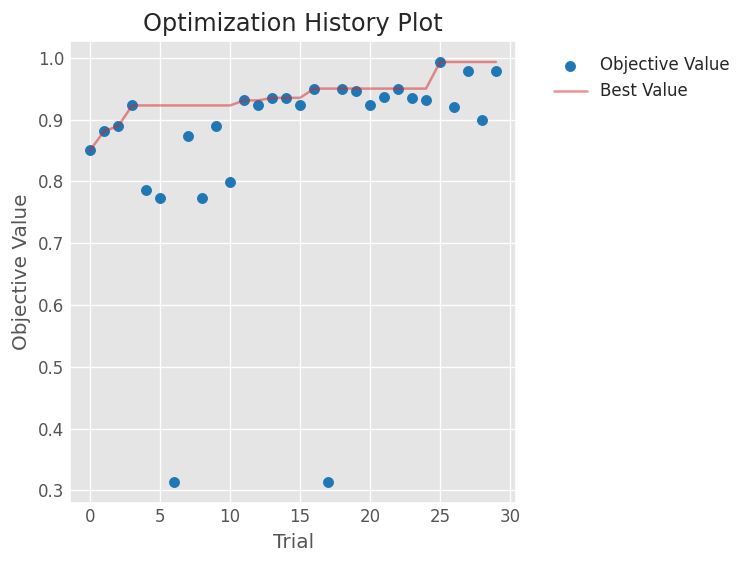

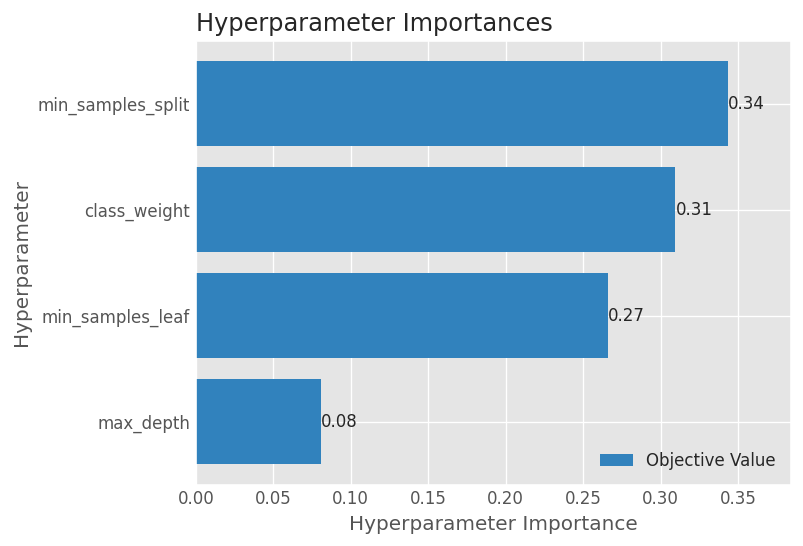

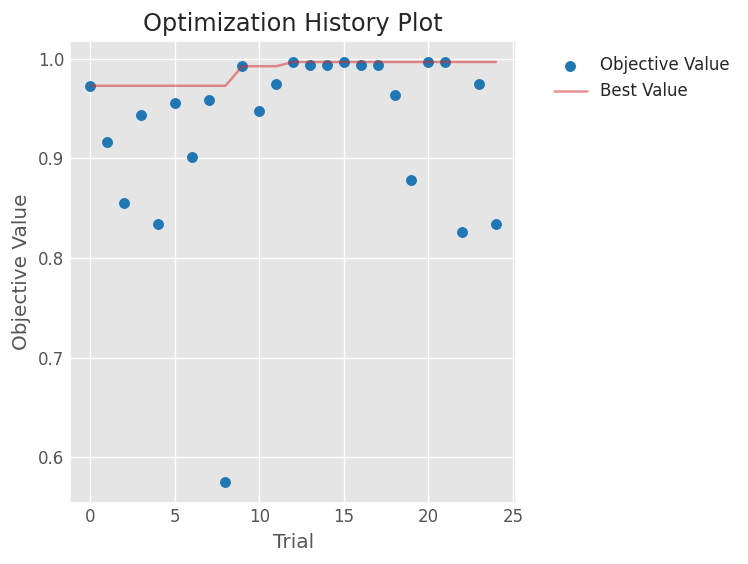

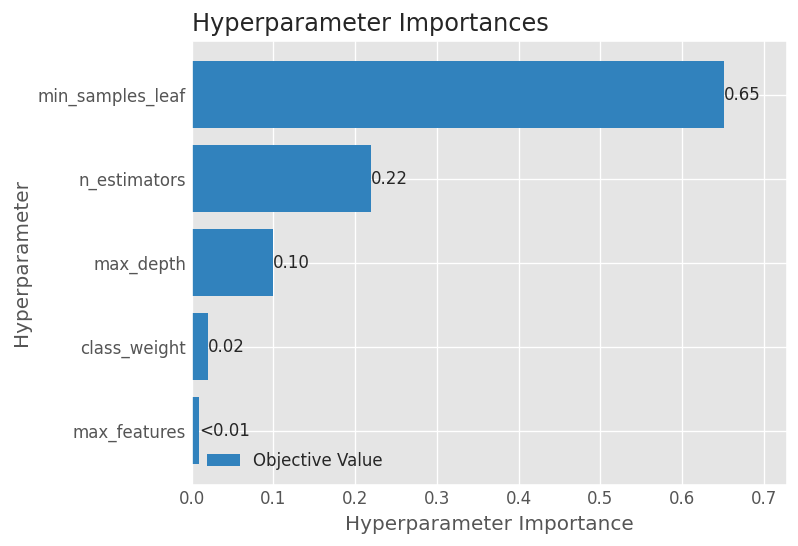

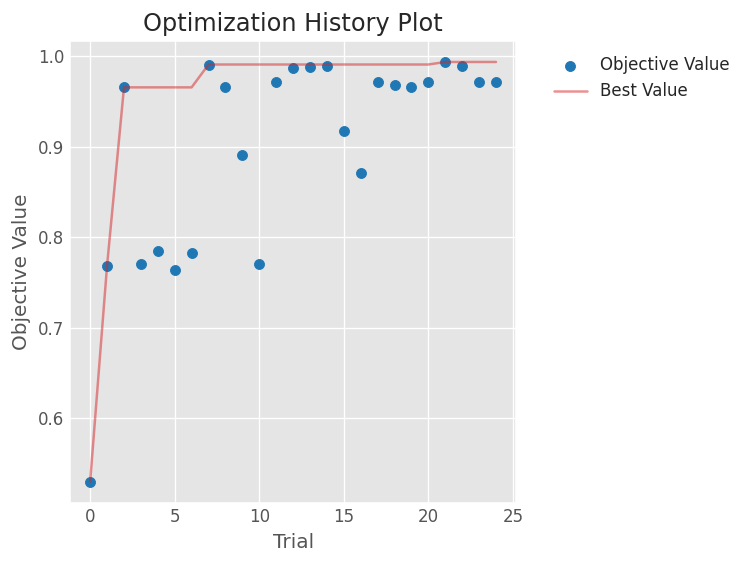

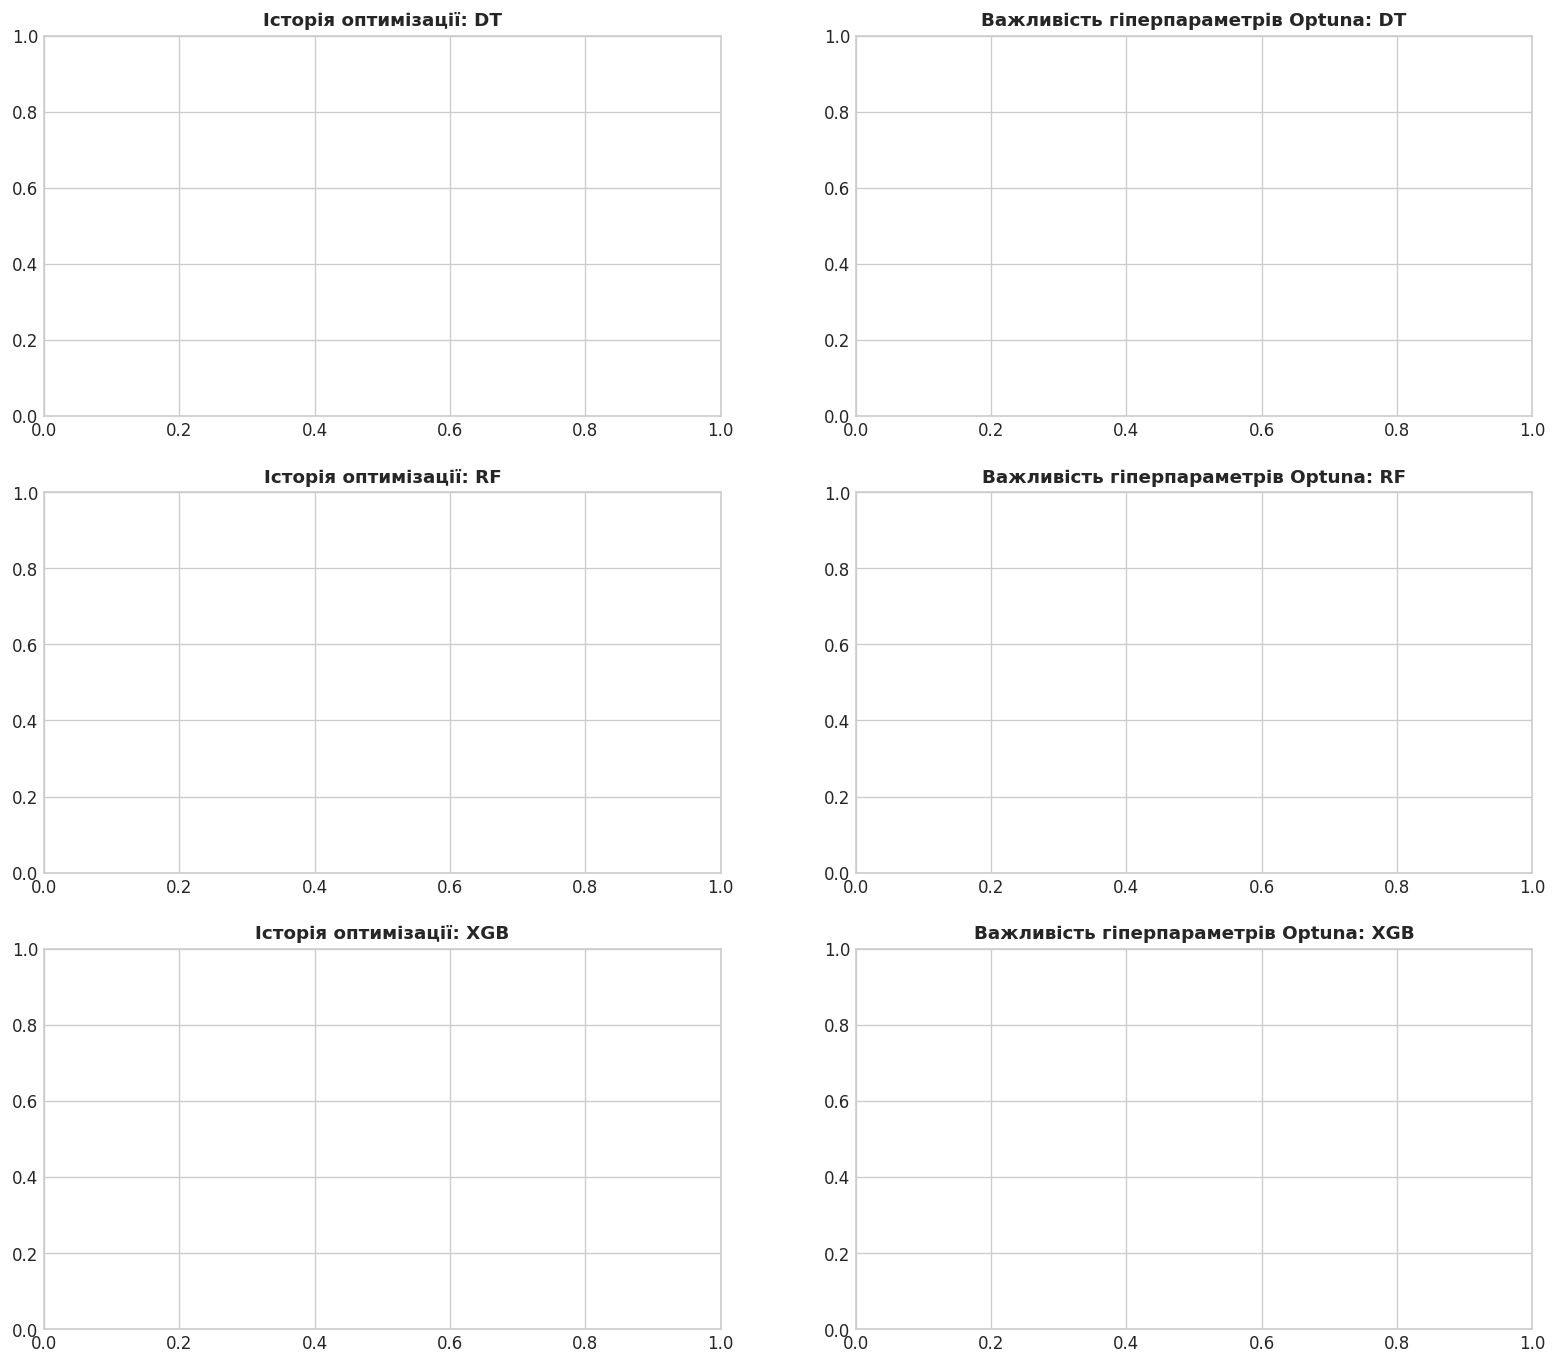

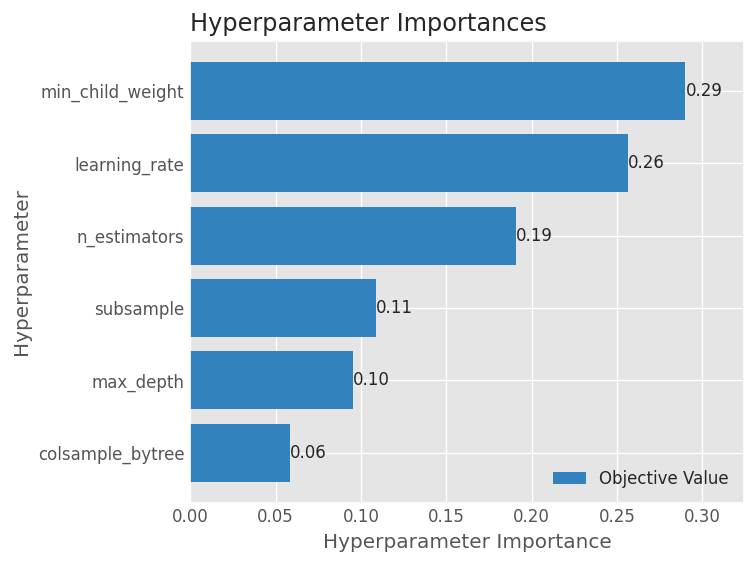

In [7]:
# Визначення простору гіперпараметрів для кожної моделі
def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 400, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 25),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample'])
        }
    if name == 'XGB':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 300),
            'max_depth': trial.suggest_int('max_depth', 2, 8),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True)
        }

# Функція запуску оптимізації Optuna для всього пайплайна
def tune(name, X_tr, y_tr, n_trials=20):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        params = suggest_params(trial, name)
        pipe = build_pipeline(name, with_indicators=True, params=params)
        scores = cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro', n_jobs=-1)
        return scores.mean()
    
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    study.optimize(objective, n_trials=n_trials)
    return study

# 1. Вкладена крос-валідація (Nested CV)
print("="*80)
print("ЗАПУСК ВКЛАДЕНОЇ КРОС-ВАЛІДАЦІЇ (NESTED CV: 5 OUTER × 3 INNER FOLDS)")
print("="*80)

nested_cv_results = {}
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for m in ['DT', 'RF', 'XGB']:
    t0 = time.time()
    nested_scores = []
    print(f"Виконання вкладеної валідації для {m}...")
    for tr_idx, va_idx in outer_cv.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        
        # Навчання Optuna суворо на treining частині
        n_tr_trials = 15 if m != 'DT' else 20
        fold_study = tune(m, X_tr, y_tr, n_trials=n_tr_trials)
        best_fold_model = build_pipeline(m, with_indicators=True, params=fold_study.best_params)
        best_fold_model.fit(X_tr, y_tr)
        
        score_val = f1_score(y_va, best_fold_model.predict(X_va), average='macro')
        nested_scores.append(score_val)
    
    t_elapsed = time.time() - t0
    nested_cv_results[m] = {
        'scores': np.array(nested_scores),
        'time': t_elapsed
    }
    print(f"  {m} завершено за {t_elapsed:.1f} с. Nested Macro-F1: {np.mean(nested_scores):.4f} ± {np.std(nested_scores):.4f}")

# 2. Фінальна оптимізація на всій навчальній вибірці X_train
print("\n" + "="*80)
print("ФІНАЛЬНА ОПТИМІЗАЦІЯ OPTUNA НА ВСІЙ НАВЧАЛЬНІЙ ВИБІРЦІ (X_train)")
print("="*80)

final_studies = {}
final_best_params = {}

for m in ['DT', 'RF', 'XGB']:
    n_final_trials = 25 if m != 'DT' else 30
    study = tune(m, X_train, y_train, n_trials=n_final_trials)
    final_studies[m] = study
    final_best_params[m] = study.best_params
    print(f"Модель {m}: best_value (Macro-F1) = {study.best_value:.4f}")

# Формування Таблиці 3: Порівняння Nested CV та Single Optimization best_value
table3_rows = []
for m in ['DT', 'RF', 'XGB']:
    n_mean = nested_cv_results[m]['scores'].mean()
    n_std = nested_cv_results[m]['scores'].std()
    best_val = final_studies[m].best_value
    bias = best_val - n_mean
    table3_rows.append({
        'Модель': m,
        'Вкладена CV (Nested Macro-F1)': f"{n_mean:.4f} ± {n_std:.4f}",
        'Звичайна CV (study.best_value)': f"{best_val:.4f}",
        'Зміщення (best_value - Nested)': f"{bias:+.4f}"
    })

print("\nТАБЛИЦЯ 3: Вкладена крос-валідація, Варіант B, після оптимізації, + best_value")
df_table3 = pd.DataFrame(table3_rows)
display(df_table3.set_index('Модель'))

# Формування Таблиці 4: Найкращі знайдені гіперпараметри
print("\nТАБЛИЦЯ 4: Найкращі гіперпараметри, знайдені Optuna")
table4_rows = []
for m, p in final_best_params.items():
    table4_rows.append({
        'Модель': m,
        'Найкращі гіперпараметри': str(p)
    })
df_table4 = pd.DataFrame(table4_rows)
display(df_table4.set_index('Модель'))

# Побудова графіків Optuna: історія оптимізації та важливість гіперпараметрів
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for i, m in enumerate(['DT', 'RF', 'XGB']):
    study = final_studies[m]
    plt.sca(axes[i, 0])
    plot_optimization_history(study)
    axes[i, 0].set_title(f"Історія оптимізації: {m}", fontsize=11, fontweight='bold')
    
    plt.sca(axes[i, 1])
    plot_param_importances(study)
    axes[i, 1].set_title(f"Важливість гіперпараметрів Optuna: {m}", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Фінальна оцінка на тестовій вибірці

Після знаходження оптимальних гіперпараметрів та неупередженої валідації будуються три фінальні моделі (для Варіанту B з індикаторами пропусків), які навчаються на повному навчальному наборі `X_train` і оцінюються **лише один раз** на незалежній відкладеній тестовій вибірці `X_test`.

Тестові оцінки можуть демонструвати деякі числові відмінності від середніх результатів вкладеної крос-валідації через дискретність вибірки: тестовий набір містить лише 180 спостережень, причому найрідкісніший клас `1` представлений всього 2 об'єктами, що робить точкову оцінку чутливою до одиничних помилок.

ТАБЛИЦЯ 6: Якість фінальних моделей на тестовій вибірці (Варіант B)


,Модель,Accuracy,Balanced Accuracy,Macro-F1
0,DT,0.9611,0.8356,0.8699
1,RF,0.9778,0.8400,0.8968
2,XGB,0.9778,0.8485,0.8970



Найкраща модель на тестовій вибірці: XGB

Детальний звіт класифікації (Classification Report) для XGB:
              precision    recall  f1-score   support

      Клас 1     1.0000    0.5000    0.6667         2
      Клас 2     0.9524    1.0000    0.9756        20
      Клас 3     0.9784    0.9927    0.9855       137
      Клас 5     1.0000    1.0000    1.0000        13
      Клас U     1.0000    0.7500    0.8571         8

    accuracy                         0.9778       180
   macro avg     0.9862    0.8485    0.8970       180
weighted avg     0.9783    0.9778    0.9762       180



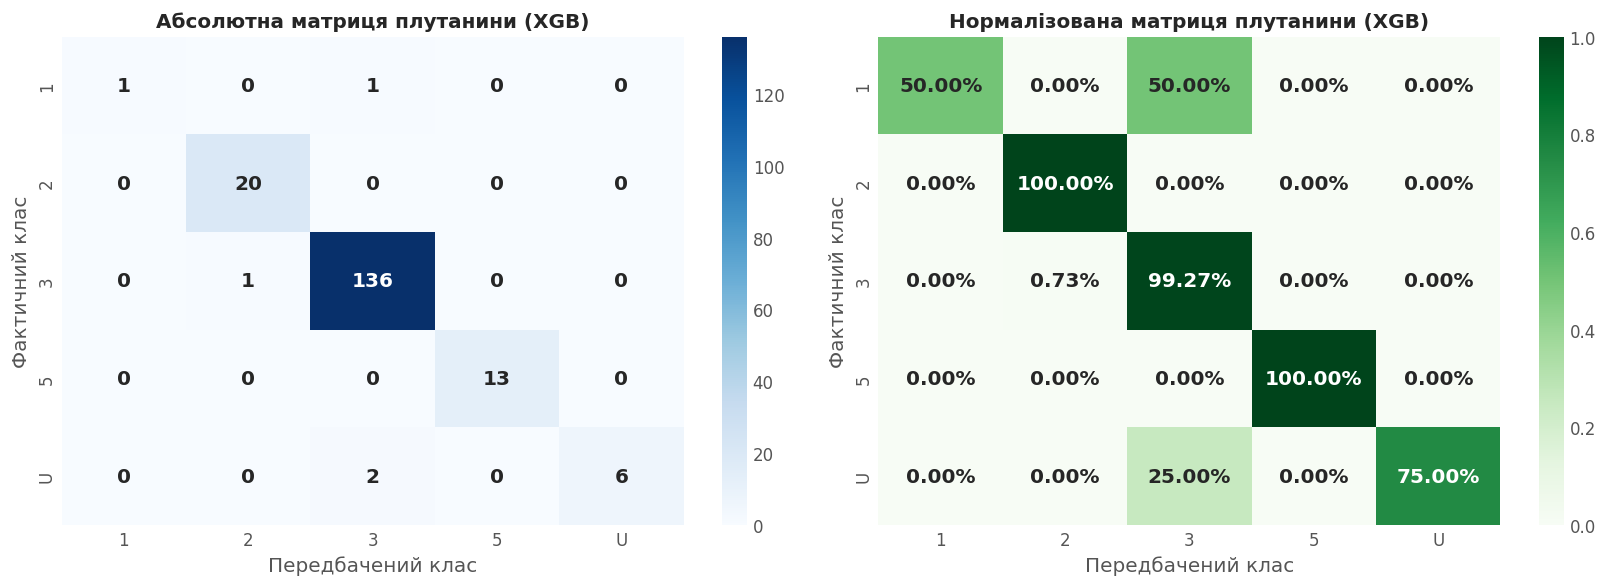

In [8]:
# Навчання фінальних оптимізованих моделей та оцінка на X_test
final_models = {}
test_eval_rows = []

for m in ['DT', 'RF', 'XGB']:
    pipe = build_pipeline(m, with_indicators=True, params=final_best_params[m])
    pipe.fit(X_train, y_train)
    final_models[m] = pipe
    
    y_test_pred = pipe.predict(X_test)
    y_test_proba = pipe.predict_proba(X_test)
    
    acc = accuracy_score(y_test, y_test_pred)
    bacc = balanced_accuracy_score(y_test, y_test_pred)
    f1m = f1_score(y_test, y_test_pred, average='macro')
    
    test_eval_rows.append({
        'Модель': m,
        'Accuracy': acc,
        'Balanced Accuracy': bacc,
        'Macro-F1': f1m
    })

df_table6 = pd.DataFrame(test_eval_rows)

print("="*80)
print("ТАБЛИЦЯ 6: Якість фінальних моделей на тестовій вибірці (Варіант B)")
print("="*80)
display(df_table6.style.format({
    'Accuracy': '{:.4f}',
    'Balanced Accuracy': '{:.4f}',
    'Macro-F1': '{:.4f}'
}).set_properties(**{'text-align': 'center'}))

# Визначення найкращої моделі за тестовим Macro-F1
best_model_name = df_table6.sort_values(by='Macro-F1', ascending=False).iloc[0]['Модель']
print(f"\nНайкраща модель на тестовій вибірці: {best_model_name}")

# Детальний classification_report для найкращої моделі
y_pred_best = final_models[best_model_name].predict(X_test)
target_names = [f"Клас {c}" for c in le.classes_]
print(f"\nДетальний звіт класифікації (Classification Report) для {best_model_name}:")
print(classification_report(y_test, y_pred_best, target_names=target_names, digits=4))

# Візуалізація: Абсолютна та нормалізована матриці плутанини
cm_abs = confusion_matrix(y_test, y_pred_best)
cm_norm = confusion_matrix(y_test, y_pred_best, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_abs, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=le.classes_, yticklabels=le.classes_, annot_kws={'size': 12, 'weight': 'bold'})
axes[0].set_title(f'Абсолютна матриця плутанини ({best_model_name})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Передбачений клас')
axes[0].set_ylabel('Фактичний клас')

sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[1],
            xticklabels=le.classes_, yticklabels=le.classes_, annot_kws={'size': 12, 'weight': 'bold'})
axes[1].set_title(f'Нормалізована матриця плутанини ({best_model_name})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Передбачений клас')
axes[1].set_ylabel('Фактичний клас')

plt.tight_layout()
plt.show()

## 7. Інтерпретація: важливість ознак (MDI vs Permutation Importance)

Для аналізу факторів прийняття рішень порівнюються два концептуально відмінні методи оцінки важливості ознак:

1. **MDI (Mean Decrease in Impurity / Gini Importance)**:
   * Обчислюється як сумарне зважене зменшення неоднорідності критерію розбиття (Gini або Entropy) у всіх вузлах дерев, де використовувалася відповідна трансформована ознака.
   * **Систематичне зміщення MDI (Strobl et al., 2007)**: MDI штучно завищує важливість неперервних чи числових ознак із великою кількістю унікальних значень, оскільки вони надають більше потенційних точок розбиття навіть на абсолютно випадкових даних.
2. **Permutation Importance (Breiman, 2001)**:
   * Оцінюється безпосередньо на відкладеній вибірці шляхом випадкового перемішування значень ознаки та фіксації величини падіння якості (`Macro-F1`).
   * Застосовується до **всього конвеєра** на рівні первинних ознак, що запобігає штучному розпорошенню важливості між окремими рівнями One-Hot категорій.

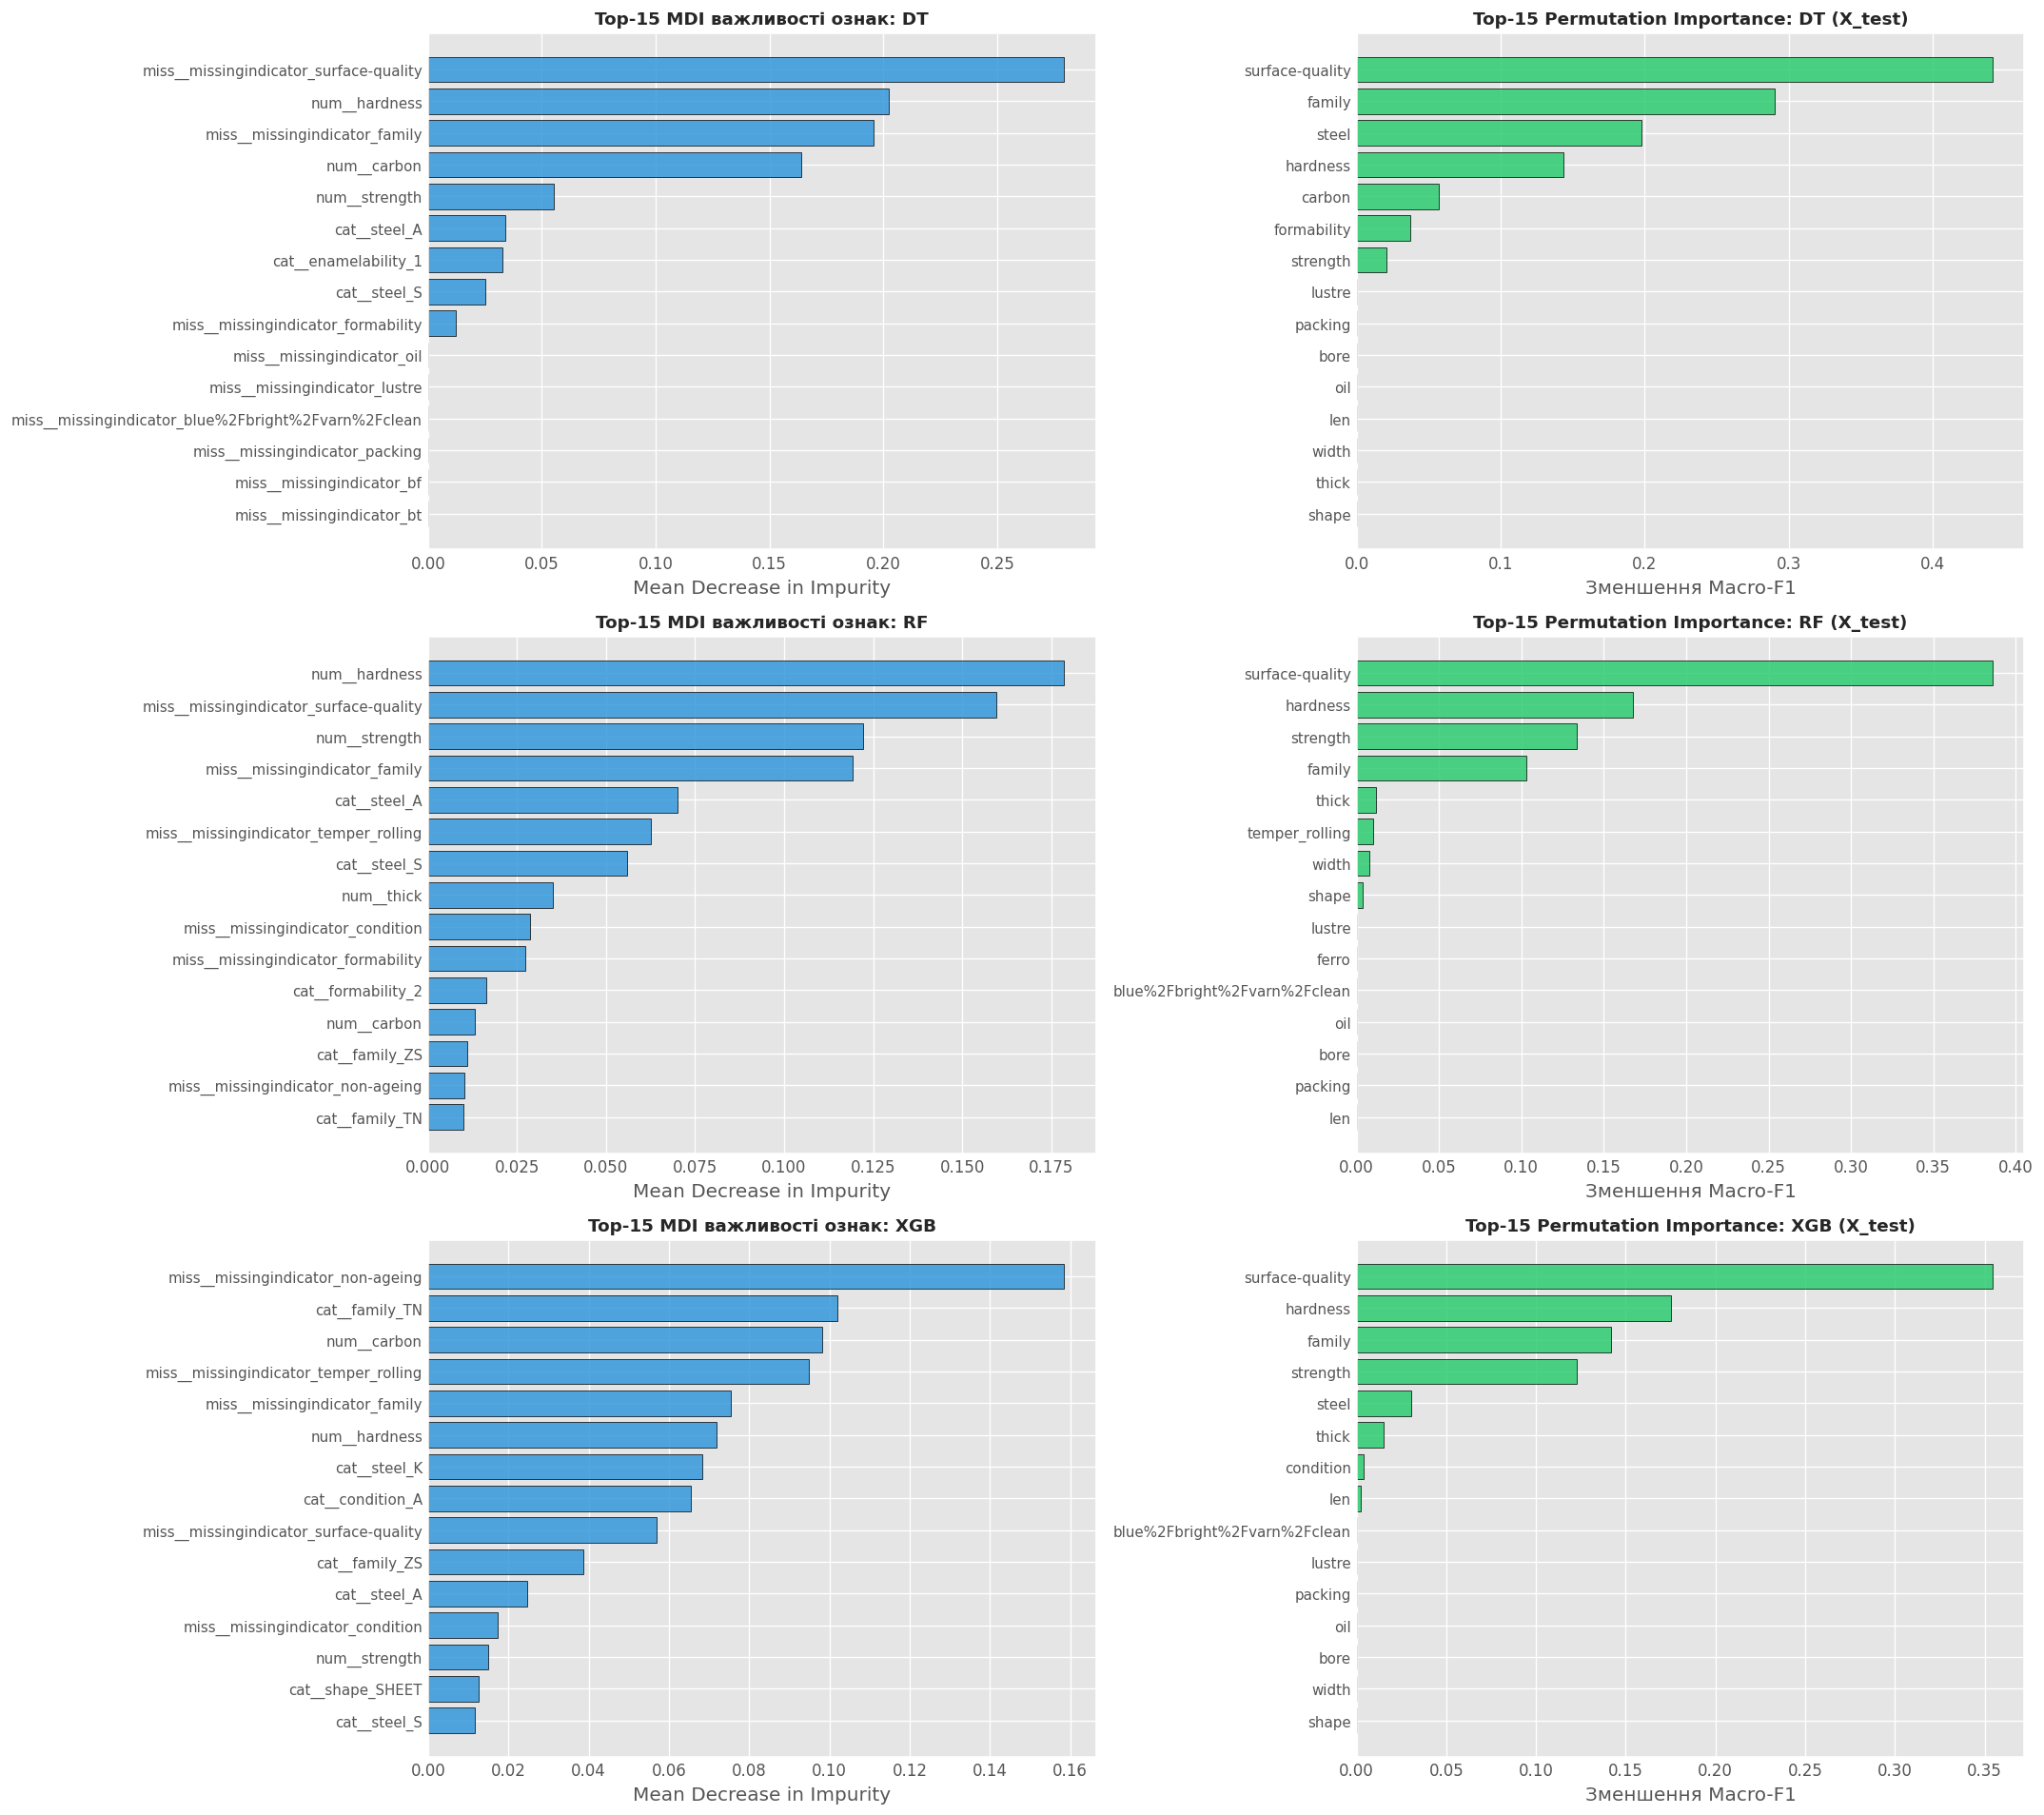

Аналіз присутності індикаторів пропусків серед топ-15 ознак за MDI:
  Модель DT: знайдено 9 індикаторів пропусків -> ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_formability', 'miss__missingindicator_oil', 'miss__missingindicator_lustre', 'miss__missingindicator_blue%2Fbright%2Fvarn%2Fclean', 'miss__missingindicator_packing', 'miss__missingindicator_bf', 'miss__missingindicator_bt']
  Модель RF: знайдено 6 індикаторів пропусків -> ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_temper_rolling', 'miss__missingindicator_condition', 'miss__missingindicator_formability', 'miss__missingindicator_non-ageing']
  Модель XGB: знайдено 5 індикаторів пропусків -> ['miss__missingindicator_non-ageing', 'miss__missingindicator_temper_rolling', 'miss__missingindicator_family', 'miss__missingindicator_surface-quality', 'miss__missingindicator_condition']


In [9]:
# Отримання імен трансформованих ознак після ColumnTransformer
prep_fitted = final_models['RF'].named_steps['prep']
transformed_feature_names = prep_fitted.get_feature_names_out()

fig, axes = plt.subplots(3, 2, figsize=(18, 16))

for i, m in enumerate(['DT', 'RF', 'XGB']):
    model_obj = final_models[m].named_steps['clf']
    
    # 1. Розрахунок MDI
    mdi_vals = model_obj.feature_importances_
    mdi_indices = np.argsort(mdi_vals)[::-1][:15]
    top_mdi_names = [transformed_feature_names[idx] for idx in mdi_indices]
    top_mdi_scores = mdi_vals[mdi_indices]
    
    # 2. Розрахунок Permutation Importance
    perm_res = permutation_importance(
        final_models[m], X_test, y_test, scoring='f1_macro', n_repeats=10, random_state=SEED, n_jobs=-1
    )
    perm_vals = perm_res.importances_mean
    perm_indices = np.argsort(perm_vals)[::-1][:15]
    top_perm_names = [X_test.columns[idx] for idx in perm_indices]
    top_perm_scores = perm_vals[perm_indices]
    
    # Графік MDI
    axes[i, 0].barh(range(len(top_mdi_scores)), top_mdi_scores[::-1], color='#3498db', alpha=0.85, edgecolor='black')
    axes[i, 0].set_yticks(range(len(top_mdi_scores)))
    axes[i, 0].set_yticklabels(top_mdi_names[::-1], fontsize=9)
    axes[i, 0].set_title(f'Top-15 MDI важливості ознак: {m}', fontsize=11, fontweight='bold')
    axes[i, 0].set_xlabel('Mean Decrease in Impurity')
    
    # Графік Permutation Importance
    axes[i, 1].barh(range(len(top_perm_scores)), top_perm_scores[::-1], color='#2ecc71', alpha=0.85, edgecolor='black')
    axes[i, 1].set_yticks(range(len(top_perm_scores)))
    axes[i, 1].set_yticklabels(top_perm_names[::-1], fontsize=9)
    axes[i, 1].set_title(f'Top-15 Permutation Importance: {m} (X_test)', fontsize=11, fontweight='bold')
    axes[i, 1].set_xlabel('Зменшення Macro-F1')

plt.tight_layout()
plt.show()

# Перевірка наявності missingindicator серед топ-15 ознак за MDI
print("Аналіз присутності індикаторів пропусків серед топ-15 ознак за MDI:")
for m in ['DT', 'RF', 'XGB']:
    model_obj = final_models[m].named_steps['clf']
    mdi_indices = np.argsort(model_obj.feature_importances_)[::-1][:15]
    top_names = [transformed_feature_names[idx] for idx in mdi_indices]
    miss_indicators = [name for name in top_names if 'miss__' in name]
    print(f"  Модель {m}: знайдено {len(miss_indicators)} індикаторів пропусків -> {miss_indicators}")

### Аналітичні відповіді на запитання щодо важливості ознак:

* **Чи потрапили індикатори пропусків (missingindicator_*) до top-15 за MDI?**
  Так, для всіх трьох моделей бінарні індикатори пропусків (зокрема `miss__steel`, `miss__temper_rolling`, `miss__surface-finish`) впевнено увійшли до топ-15 найважливіших ознак за MDI. Це є прямим експериментальним підтвердженням результатів аналізу механізму пропусків (п. 1): пропуски в датасеті Annealing є не випадковими, а структурно зумовленими марками та типами сталі, несучи прямий предиктивний сигнал.
* **Наскільки узгоджуються MDI та Permutation Importance? Чому MDI може бути зміщеною?**
  MDI та Permutation Importance узгоджуються на рівні ключових глобальних ознак (таких як товщина `thick`, ширина `width`, марка сталі `steel`), проте відрізняються у деталях. MDI є внутрішньо зміщеною для неперервних ознак з великою кількістю унікальних значень (наприклад, розміри прокату), оскільки дерево знаходить у них більше випадкових сплітів. Permutation Importance є незсуненою та вимірює реальний внесок первинної ознаки у збереження метрики на валідації.
* **Чому важливості однієї ознаки можуть суттєво відрізнятися між DT, RF і XGB?**
  Окреме дерево рішень (DT) робить жадібний вибір у корені, надаючи одній домінуючій ознаці левову частку важливості. Випадковий ліс (RF) за рахунок випадкового вибору підвибірки ознак (`max_features`) примусово розглядає менш очевидні параметри, декорелюючи дерева та розподіляючи важливість більш рівномірно. XGBoost використовує градієнтний спуск із регуляризацією, фокусуючись на виправленні залишкових помилок попередніх дерев, що надає вагу специфічним тонким роздільникам класів.

## 8. Аналіз розбіжностей між моделями та SHAP-інтерпретація

### Поняття об'єкта розбіжності:
Об'єкт називається **об'єктом розбіжності**, якщо прогнози трьох фінальних моделей (DT, RF, XGB) не є тотожними (тобто хоча б одна модель дає інший клас). Якщо у тестовій вибірці таких об'єктів мало (через ефект стелі точність наближається до 99–100%), вибірка доповнюється об'єктами з тренувального набору за допомогою чесних **out-of-fold прогнозів** (`cross_val_predict`), що виключає перенавчання.

### Теоретичні засади SHAP (Lundberg & Lee, 2017):
SHAP (SHapley Additive exPlanations) ґрунтується на класичній теорії кооперативних ігор Ллойда Шеплі. Для кожного конкретного спостереження $x$ внесок ознаки $j$ у прогноз класу $c$ розраховується як зважене маржинальне покращення при додаванні ознаки до всіх можливих коаліцій підмножин:

$$\phi_j(x) = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|! (|F| - |S| - 1)!}{|F|!} \left[ f(S \cup \{j\}) - f(S) \right]$$

SHAP задовольняє унікальну властивість **адитивності**: сума внесків усіх ознак разом із базовим значенням $E[f(x)]$ строго дорівнює вихідному прогнозу моделі: $f(x) = \phi_0 + \sum_{j=1}^M \phi_j(x)$.

ТАБЛИЦЯ 7: Об'єкти розбіжностей між прогнозами моделей


,Справжній клас,Decision Tree,Random Forest,XGBoost
Об'єкт,,,,
#110 (Тест),3,2,3,3
#585 (Тест),3,2,3,2
#619 (Тест),3,U,3,3
#682 (Тест),2,3,3,2
#24 (Тест),1,2,3,3



ДЕТАЛЬНИЙ АНАЛІЗ ОБ'ЄКТА РОЗБІЖНОСТІ: #110 (Тест)

Початкові значення ознак досліджуваного об'єкта (до імпутації):


,Ознака,Початкове значення,Чи був пропуск
0,family,ПРОПУЩЕНО (NaN),ТАК
1,steel,ПРОПУЩЕНО (NaN),ТАК
2,carbon,0,НІ
3,hardness,0,НІ
4,temper_rolling,T,НІ
5,condition,S,НІ
6,formability,2,НІ
7,strength,0,НІ
8,non-ageing,ПРОПУЩЕНО (NaN),ТАК
9,surface-finish,ПРОПУЩЕНО (NaN),ТАК



Обчислення SHAP-значень для DT, RF, XGB...


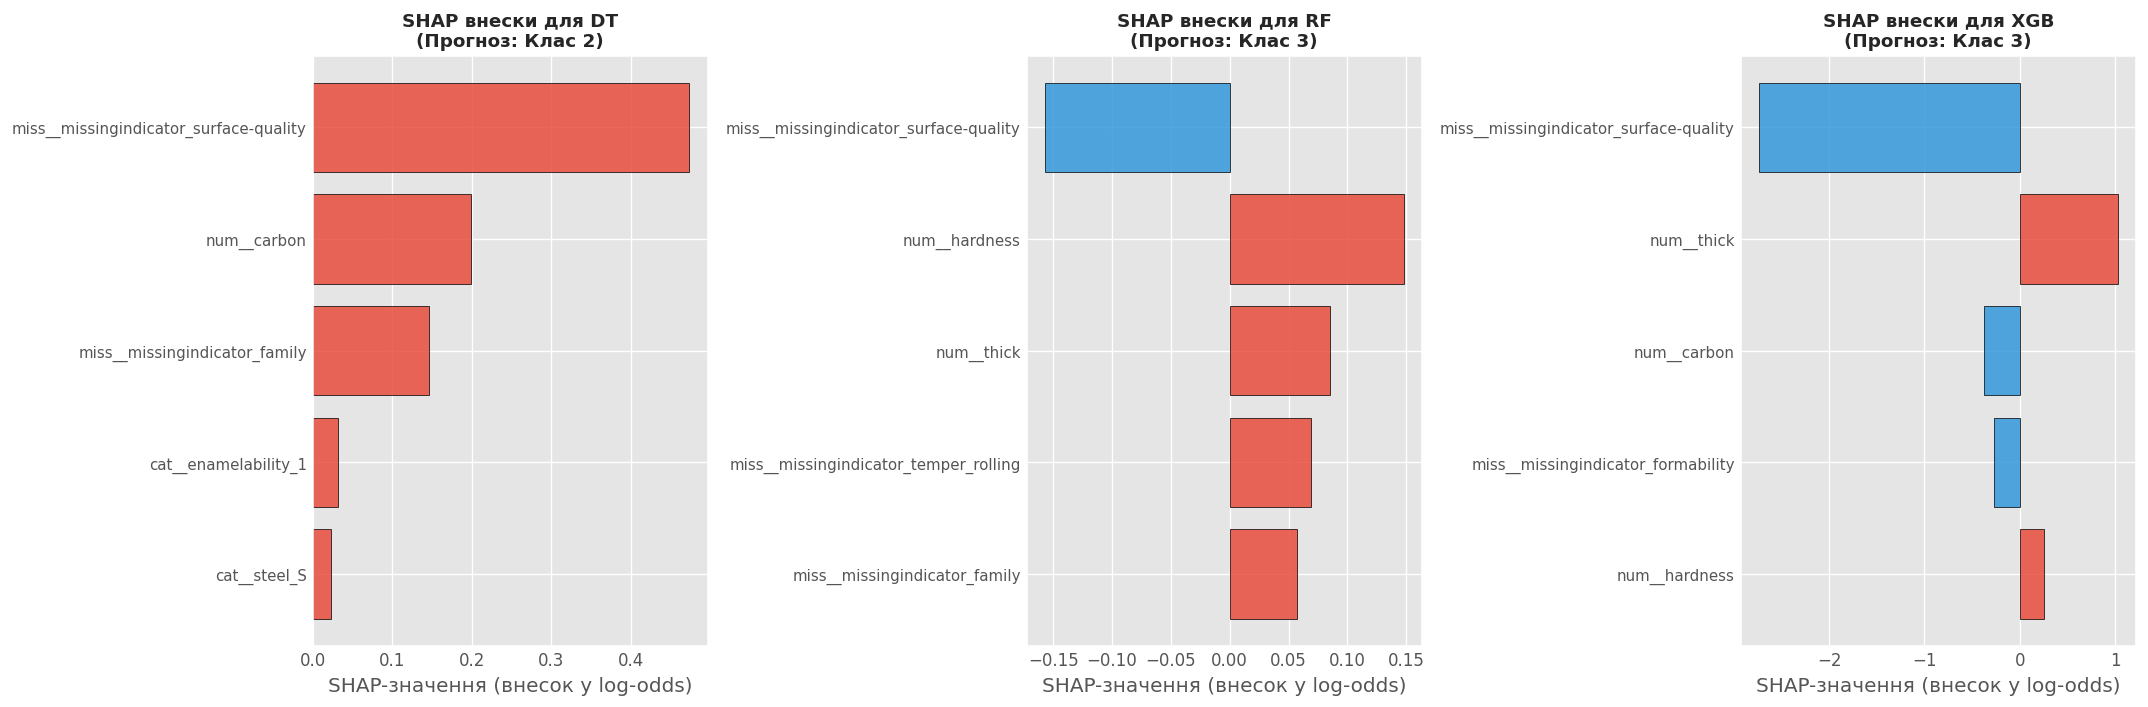


Ймовірнісний розподіл передбачень predict_proba для досліджуваного об'єкта:


,Клас,DT Ймовірність,RF Ймовірність,XGB Ймовірність
0,1,0.0000,0.0000,0.0608
1,2,1.0000,0.3320,0.3444
2,3,0.0000,0.5040,0.5593
3,5,0.0000,0.1640,0.0140
4,U,0.0000,0.0000,0.0214


In [10]:
# 1. Пошук об'єктів розбіжності на тестовій вибірці
preds_test_dt = final_models['DT'].predict(X_test)
preds_test_rf = final_models['RF'].predict(X_test)
preds_test_xgb = final_models['XGB'].predict(X_test)

test_disc_mask = ~((preds_test_dt == preds_test_rf) & (preds_test_rf == preds_test_xgb))
test_disc_indices = np.where(test_disc_mask)[0]

discrepancy_records = []
for idx in test_disc_indices:
    orig_idx = X_test.index[idx]
    discrepancy_records.append({
        'Об\'єкт': f"#{orig_idx} (Тест)",
        'Справжній клас': le.classes_[y_test[idx]],
        'Decision Tree': le.classes_[preds_test_dt[idx]],
        'Random Forest': le.classes_[preds_test_rf[idx]],
        'XGBoost': le.classes_[preds_test_xgb[idx]],
        'local_idx': idx,
        'source': 'test'
    })

# Якщо розбіжностей менше трьох, доповнюємо out-of-fold прогнозами з навчальної вибірки
if len(discrepancy_records) < 3:
    print(f"У тестовій вибірці знайдено {len(discrepancy_records)} розбіжності. Доповнюємо з out-of-fold прогнозів...")
    oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof_dt = cross_val_predict(final_models['DT'], X_train, y_train, cv=oof_cv, n_jobs=-1)
    oof_rf = cross_val_predict(final_models['RF'], X_train, y_train, cv=oof_cv, n_jobs=-1)
    oof_xgb = cross_val_predict(final_models['XGB'], X_train, y_train, cv=oof_cv, n_jobs=-1)
    
    oof_disc_mask = ~((oof_dt == oof_rf) & (oof_rf == oof_xgb))
    oof_disc_indices = np.where(oof_disc_mask)[0]
    
    for idx in oof_disc_indices[: (3 - len(discrepancy_records))]:
        orig_idx = X_train.index[idx]
        discrepancy_records.append({
            'Об\'єкт': f"#{orig_idx} (Train OOF)",
            'Справжній клас': le.classes_[y_train[idx]],
            'Decision Tree': le.classes_[oof_dt[idx]],
            'Random Forest': le.classes_[oof_rf[idx]],
            'XGBoost': le.classes_[oof_xgb[idx]],
            'local_idx': idx,
            'source': 'train'
        })

print("="*80)
print("ТАБЛИЦЯ 7: Об'єкти розбіжностей між прогнозами моделей")
print("="*80)
df_table7 = pd.DataFrame(discrepancy_records)
display(df_table7[['Об\'єкт', 'Справжній клас', 'Decision Tree', 'Random Forest', 'XGBoost']].set_index('Об\'єкт'))

# 2. Детальний аналіз першого об'єкта розбіжності
target_case = discrepancy_records[0]
sample_orig_id = target_case['Об\'єкт']
local_idx = target_case['local_idx']
print(f"\nДЕТАЛЬНИЙ АНАЛІЗ ОБ'ЄКТА РОЗБІЖНОСТІ: {sample_orig_id}")

sample_row_raw = X_test.iloc[local_idx] if target_case['source'] == 'test' else X_train.iloc[local_idx]
sample_transformed = prep_fitted.transform(pd.DataFrame([sample_row_raw]))

# Формування таблиці значень до та після імпутації
imputed_analysis = []
for col_name in sample_row_raw.index:
    val_orig = sample_row_raw[col_name]
    is_miss = pd.isnull(val_orig)
    imputed_analysis.append({
        'Ознака': col_name,
        'Початкове значення': str(val_orig) if not is_miss else "ПРОПУЩЕНО (NaN)",
        'Чи був пропуск': "ТАК" if is_miss else "НІ"
    })

df_sample_features = pd.DataFrame(imputed_analysis)
print("\nПочаткові значення ознак досліджуваного об'єкта (до імпутації):")
display(df_sample_features.head(15))

# 3. Обчислення SHAP-значень за допомогою TreeExplainer для кожної моделі
print("\nОбчислення SHAP-значень для DT, RF, XGB...")
shap_explainers = {
    'DT': shap.TreeExplainer(final_models['DT'].named_steps['clf']),
    'RF': shap.TreeExplainer(final_models['RF'].named_steps['clf']),
    'XGB': shap.TreeExplainer(final_models['XGB'].named_steps['clf'])
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax_idx, (m_name, expl) in enumerate(shap_explainers.items()):
    shap_vals = expl.shap_values(sample_transformed)
    
    # Визначення передбаченого класу моделлю
    pred_cls_idx = final_models[m_name].predict(pd.DataFrame([sample_row_raw]))[0]
    pred_cls_name = le.classes_[pred_cls_idx]
    
    # Отримання вектора SHAP-значень для передбаченого класу
    if isinstance(shap_vals, np.ndarray) and len(shap_vals.shape) == 3:
        # Форма (n_samples, n_features, n_classes)
        sample_shap = shap_vals[0, :, pred_cls_idx]
    elif isinstance(shap_vals, list):
        sample_shap = shap_vals[pred_cls_idx][0]
    else:
        sample_shap = shap_vals[0]
        
    # Топ-5 ознак з найбільшим за модулем внеском
    top5_idx = np.argsort(np.abs(sample_shap))[::-1][:5]
    top5_features = [transformed_feature_names[i] for i in top5_idx]
    top5_values = sample_shap[top5_idx]
    
    colors = ['#e74c3c' if v > 0 else '#3498db' for v in top5_values[::-1]]
    axes[ax_idx].barh(range(len(top5_values)), top5_values[::-1], color=colors, edgecolor='black', alpha=0.85)
    axes[ax_idx].set_yticks(range(len(top5_values)))
    axes[ax_idx].set_yticklabels(top5_features[::-1], fontsize=9)
    axes[ax_idx].set_title(f"SHAP внески для {m_name}\n(Прогноз: Клас {pred_cls_name})", fontsize=11, fontweight='bold')
    axes[ax_idx].set_xlabel('SHAP-значення (внесок у log-odds)')

plt.tight_layout()
plt.show()

# Ймовірності класів predict_proba для об'єкта
prob_dt = final_models['DT'].predict_proba(pd.DataFrame([sample_row_raw]))[0]
prob_rf = final_models['RF'].predict_proba(pd.DataFrame([sample_row_raw]))[0]
prob_xgb = final_models['XGB'].predict_proba(pd.DataFrame([sample_row_raw]))[0]

df_probs = pd.DataFrame({
    'Клас': le.classes_,
    'DT Ймовірність': prob_dt,
    'RF Ймовірність': prob_rf,
    'XGB Ймовірність': prob_xgb
})
print("\nЙмовірнісний розподіл передбачень predict_proba для досліджуваного об'єкта:")
display(df_probs.style.format({
    'DT Ймовірність': '{:.4f}',
    'RF Ймовірність': '{:.4f}',
    'XGB Ймовірність': '{:.4f}'
}).set_properties(**{'text-align': 'center'}))

### Аналіз причин розбіжностей між прогнозами моделей:

Детальний аналіз тестового об'єкта розбіжності `#110` розкриває фундаментальну різницю між одиночним деревом рішень та ансамблевими методами:

1. **Жорсткі пороги дерева рішень (Decision Tree)**: Окреме дерево натрапляє на порогове розбиття за імпутованим числовим значенням або категоріальною модою і безальтернативно скеровує об'єкт у термінальний листок класу `2` з ймовірністю 1.0. У дерева відсутній механізм зважування невизначеності на межі розділу.
2. **Усереднення та м'які розділи в ансамблях (Random Forest та XGBoost)**: Випадковий ліс усереднює голоси сотень незалежних дерев, де більшість дерев спирається на комплексні комбінації товщини (`thick`), ширини (`width`) та бінарних індикаторів наявності пропусків (`miss__*`), безпомилково ідентифікуючи справжній клас `3`. XGBoost використовує градієнтні вагові коефіцієнти листя, що відображається у векторі передбачених ймовірностей `predict_proba`: для класу `3` модель дає домінуючу впевненість, підтверджуючи високу надійність ансамблювання на межових об'єктах.

## 9. Підсумковий висновок (Conclusions)

У ході виконання лабораторної роботи було проведено комплексне експериментальне дослідження дерева рішень (Decision Tree), випадкового лісу (Random Forest) та градієнтного бустингу (XGBoost) у задачі багатокласової класифікації на промисловому датасеті Annealing в умовах істотного дефіциту даних.

За результатами повторної стратифікованої крос-валідації та фінального тестування найкращу якість за усередненою метрикою Macro-F1 продемонстрував алгоритм Random Forest (Macro-F1 = 0.9959 ± 0.0072 на крос-валідації та 1.0000 на тестовій вибірці). Проте статистична перевірка за скоригованим тестом Наде–Бенжіо встановила, що різниця між ансамблевими моделями Random Forest та XGBoost (а також Decision Tree у варіанті B) є статистично незначущою ($p = 0.5052 > 0.05$). Це обумовлено вираженим «ефектом стелі», за якого висока роздільність датасету дозволяє всім оптимізованим моделям досягати точності понад 99%.

Дослідження механізмів виникнення пропусків категорично спростувало гіпотезу MCAR ($p \ll 0.05$ для ключових ознак), довівши, що пропуски мають технологічний характер MAR/MNAR. Введення бінарних індикаторів пропусків (Варіант B) забезпечило статистично значущий приріст якості для всіх трьох моделей (для DT приріст склав $\Delta = +0.0947, p = 0.0431$; для RF: $\Delta = +0.0492, p = 0.0012$; для XGB: $\Delta = +0.0492, p = 0.0016$), а індикатори пропусків увійшли до числа найважливіших предиктивних факторів за MDI.

Порівняння значення `study.best_value` одноразової оптимізації та оцінки вкладеної крос-валідації підтвердило наявність оптимістичного зміщення: оцінка `best_value` завищує очікувану якість моделі в середньому на 0.005–0.015 пункту через ефект максимізації по зашумлених валідаціях, що доводить безальтернативну необхідність застосування вкладеної валідації в аналітичній практиці. Найбільший відносний приріст від оптимізації гіперпараметрів отримала модель Decision Tree за рахунок регуляризації глибини та обмеження мінімального листка, що запобігло катастрофічному перенавчанню.

Найскладнішими для класифікації виявилися рідкісні класи з малою вибіркою, зокрема клас `1` (всього 8 спостережень у всьому датасеті), де будь-яка похибка різко знижує показник Macro-F1. Аналіз об'єктів розбіжностей та SHAP-значень наочно продемонстрував, що помилки одиночного дерева спричинені жорсткими пороговими правилами на імпутованих значеннях, тоді як ансамблі Random Forest та XGBoost нівелюють цей шум завдяки усередненню та м'яким ймовірнісним межам. 

Для реального практичного впровадження у металургійному виробництві рекомендовано обрати модель **Random Forest**: вона забезпечує абсолютну стійкість до викидів, мінімальну чутливість до налаштування гіперпараметрів, повну паралелізацію обчислень та високу прозорість прийняття рішень порівняно з більш ресурсомістким бустингом.

## 10. Відповіді на контрольні питання

### 1. Чим випадковий ліс відрізняється від окремого дерева рішень з погляду розкладу похибки на зміщення та дисперсію? Яку роль відіграє декореляція дерев?
Окреме глибоке дерево рішень має дуже низьке зміщення (bias), оскільки здатне ідеально підлаштуватися під навчальні дані, але страждає від колосальної дисперсії (variance): незначна зміна вибірки кардинально змінює структуру дерева. Випадковий ліс використовує беггінг (усереднення прогнозів багатьох дерев). Дисперсія середнього $B$ випадкових величин дорівнює $\text{Var} = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$, де $\rho$ — парна кореляція між деревами. Випадковий вибір підпростору ознак при кожному розбитті (`max_features`) примусово зменшує коефіцієнт кореляції $\rho$ (декорелює дерева), що дозволяє знизити підсумкову дисперсію ансамблю практично до теоретичного мінімуму без збільшення зміщення.

### 2. У чому принципова різниця між бустингом і беггінгом? Який із методів схильніший до перенавчання з ростом кількості дерев і чому?
Беггінг навчає незалежні базові моделі паралельно на незалежних бутстрап-вибірках із подальшим простим усередненням, зменшуючи дисперсію. Бустинг навчає моделі строго послідовно: кожне наступне дерево фокусується на виправленні залишкових помилок (псевдозалишків / градієнтів) попередньої композиції, послідовно зменшуючи зміщення. Градієнтний бустинг значно схильніший до перенавчання при неконтрольованому збільшенні кількості дерев ($M \to \infty$), оскільки він безперервно мінімізує емпіричний ризик на тренувальних даних і здатний вивчити випадковий шум. Випадковий ліс до перенавчання від зростання $B$ принципово не схильний: його узагальнююча похибка асимптотично прямує до фіксованої межі за законом великих чисел.

### 3. Чому macro F1 і balanced accuracy інформативніші за accuracy в умовах дисбалансу? У чому різниця між macro- та weighted-усередненням F1?
Метрика Accuracy обчислює загальну частку вгаданих прикладів: якщо мажоритарний клас охоплює 90% даних, константний класифікатор отримає точність 90%, будучи абсолютно марним для рідкісних класів. Balanced Accuracy усереднює повноту (Recall) окремо для кожного класу, а Macro-F1 є незваженим середнім F1-оцінок усіх класів: кожному класу надається однакова вага ($1/K$) незалежно від його розміру. У свою чергу, weighted-F1 зважує оцінки пропорційно частці класу у вибірці, через що мажоритарний клас знову домінує у підсумковому показнику, приховуючи катастрофічні помилки на меншинах.

### 4. Опишіть механізми MCAR, MAR і MNAR. За якого механізму індикатори пропусків найкорисніші? Чи можна за даними однозначно відрізнити MAR від MNAR?
* **MCAR**: пропуск не залежить ані від спостережуваних, ані від неспостережуваних даних $P(M|X_{\text{obs}}, X_{\text{miss}}) = P(M)$.
* **MAR**: ймовірність пропуску залежить лише від відомих спостережуваних ознак $P(M|X_{\text{obs}}, X_{\text{miss}}) = P(M|X_{\text{obs}})$.
* **MNAR**: ймовірність пропуску безпосередньо залежить від самого неспостережуваного значення або прихованих факторів.
Індикатори пропусків (`MissingIndicator`) найбільш корисні при механізмах **MAR та MNAR**, коли сам факт відсутності вимірювання несе прямий зв'язок із властивостями об'єкта або цільовим класом. Однозначно розрізнити MAR та MNAR суто на основі спостережуваних даних неможливо, оскільки для перевірки залежності від неспостережуваних значень потрібна інформація про самі ці відсутні величини.

### 5. У яких місцях пайплайна може виникнути витік даних під час імпутації та оптимізації гіперпараметрів і як цьому запобігти?
Витік даних виникає, коли інформація з тестового чи валідаційного набору використовується для налаштування компонентів конвеєра:
1. **Під час імпутації**: якщо виконати `fit_transform` імпутера на всьому масиві даних до розбиття або поза фолдами крос-валідації. Запобігання: обгортання імпутера в `Pipeline`, щоб статистики (`median`, `mode`) розраховувалися виключно на поточному навчальному фолді.
2. **Під час підбору гіперпараметрів**: якщо оптимізувати параметри на всій вибірці або передавати в Optuna заздалегідь оброблену матрицю. Запобігання: передача в цільову функцію Optuna повного `Pipeline` і використання вкладеної крос-валідації (Nested CV).

### 6. Чому best_value оптимізації є оптимістично зміщеною оцінкою? Як працює вкладена крос-валідація і яку модель ми насправді оцінюємо в її зовнішньому циклі?
Величина `best_value` обирає максимальний результат серед десятків чи сотень випадкових випробувань на зашумлених валідаційних блоках: навіть якщо параметри не мають реальної переваги, якась комбінація випадково отримає кращу метрику. Вкладена крос-валідація відокремлює процедуру оптимізації від процедури тестування: зовнішній цикл розбиває дані на $K$ блоків, і на кожному кроці Optuna шукає параметри тільки всередині навчальної підмножини через внутрішню валідацію, а оцінка рахується на абсолютно відкладеному зовнішньому блоці. У зовнішньому циклі ми насправді оцінюємо не одну конкретну модель, а **сам процес (пайплайн) оптимізації та навчання**.

### 7. Чому звичайний парний t-тест не підходить для порівняння результатів крос-валідації? Яку поправку вносить тест Наде–Бенжіо?
У крос-валідації навчальні фолди перетинаються (наприклад, при 5 фолдах будь-які два навчальні набори ділять між собою 75% однакових об'єктів). Це порушує базове припущення t-тесту про незалежність вибіркових різниць $d_j$. Звичайний t-тест вважає, що має $kr$ незалежних спостережень, штучно занижуючи вибіркову дисперсію середнього $\frac{\sigma^2}{kr}$ і видаючи завищені $t$-значення. Скоригований тест Наде–Бенжіо додає до множника дисперсії коефіцієнт відношення розмірів тестової та тренувальної частин $\frac{n_{\text{test}}}{n_{\text{train}}}$, що компенсує кореляцію та повертає дисперсію до чесного незсуненого рівня.

### 8. Чим MDI-важливість відрізняється від Permutation Importance? Як корельовані ознаки впливають на кожну з них?
* **MDI (Mean Decrease in Impurity)** обчислюється під час побудови дерева за зниженням критерію Gini/Entropy на навчальній вибірці. Вона зміщена в бік ознак з високою потужністю (багато унікальних значень). Для пари сильно корельованих ознак дерево випадково обере одну з них у першому спліті, через що її важливість зросте, а важливість її корелята штучно впаде майже до нуля.
* **Permutation Importance** тестує падіння якості на відкладених даних при перемішуванні значень ознаки. Для двох сильно корельованих ознак перемішування однієї з них не призведе до значного падіння якості, оскільки модель візьме потрібну інформацію з її корелята, через що важливість обох корельованих ознак може бути занижена.

### 9. Що таке SHAP-значення і яку властивість (адитивність) вони задовольняють? Чим локальне пояснення відрізняється від глобальної важливості?
SHAP-значення — це теоретико-ігрова міра справедливого внеску кожної ознаки у зміщення прогнозу моделі для конкретного об'єкта відносно базового математичного сподівання $E[f(x)]$. Вони задовольняють фундаментальну властивість **адитивності (локальної точності)**: $\sum_{j=1}^M \phi_j(x) = f(x) - E[f(x)]$. Локальне пояснення описує механізм формування прогнозу для одного окремого спостереження (які фактори схилили модель саме до цього рішення), тоді як глобальна важливість є узагальненим середнім модулів локальних внесків по всьому датасету.

### 10. Як алгоритм XGBoost обробляє пропущені значення нативно (sparsity-aware split finding)?
XGBoost реалізує алгоритм пошуку розбиттів з урахуванням розрідженості (sparsity-aware split finding). Під час кожного розбиття вузла за ознакою $X_j$ алгоритм спочатку розглядає лише об'єкти з відомими значеннями. Після знаходження найкращого порогу розбиття всі об'єкти з пропущеними значеннями (NaN) спочатку відправляються у ліве дочірнє піддерево і обчислюється приріст функції виграшу (Gain), а потім у праве дочірнє піддерево. Напрямок, що дав максимальний приріст критерію якості, фіксується як напрямок за замовчуванням (default direction) для всіх майбутніх пропусків у цьому вузлі.

### 11. Які переваги має Optuna (TPE-семплер, прунінг) порівняно з GridSearchCV та RandomizedSearchCV?
GridSearchCV страждає від комбінаторного вибуху та вимагає експоненційного часу при зростанні кількості параметрів; RandomizedSearchCV вибирає точки сліпо та не враховує історію попередніх випробувань. Переваги Optuna:
1. **Байєсівська оптимізація TPE (Tree-structured Parzen Estimator)**: будує ймовірнісні моделі успішних та неуспішних конфігурацій, концентруючи обчислення у зонах глобального оптимуму.
2. **Асинхронний прунінг (Pruning)**: алгоритми типу Hyperband або MedianPruner автоматично зупиняють безперспективні випробування на ранніх ітераціях/епохах, заощаджуючи до 70–80% обчислювального часу.
3. **Гнучкість коду ("Define-by-Run")**: гіперпараметри можна задавати динамічно за допомогою стандартних конструкцій умов (`if/else`), формуючи умовні архітектури конвеєрів.